# Uncertainty quantification on a ballistic example

This notebook is a hands-on course in **uncertainty quantification (UQ)**. It uses one small, transparent
model throughout: a ball kicked through air with drag, lift and wind. The physics is simple enough to
understand completely, so all the attention can go to the methods:

| § | Topic | Question it answers |
|---|---|---|
| 0 | Setup and the model | What does the simulator compute, and how accurately? |
| 1 | Deterministic exploration | How does each input change the outputs? |
| 2 | Uncertainty propagation | Given uncertain inputs, how uncertain is the range? |
| 3 | Design of experiments | Where should we run an expensive simulator? |
| 4 | Surrogate models | Can a cheap model replace the simulator? |
| 5 | Sensitivity analysis | Which input uncertainties matter? |
| 6 | Robust optimisation | Which design hits the target despite the uncertainty? |
| 7 | Bayesian calibration | What do measurements tell us about an uncertain parameter? |
| 8 | Wrap-up | How do the pieces fit together? |

The numerics come from the tested package `uq_core`, which also powers the interactive app
(`uq_demo/README.md`). The core algorithms are written out in short cells and then checked in one line
against `uq_core`; `uq_core` is used as a black box only for the plumbing. Plotting lives in
`ballistic_helpers.py`, next to this notebook.

Every section starts with **learning goals** and ends with **takeaways** and **exercises**. All random
seeds are fixed, so the notebook is reproducible; a full run takes one to two minutes on a laptop.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy import stats
from scipy.stats import qmc

import ballistic_helpers as bh
from uq_core import calibration, doe, params, propagation, robust, sensitivity, surrogate
from uq_core.ballistics import AREA, DIAMETER, G, K_AERO, RHO, T_MAX, vacuum_trajectory

%matplotlib inline
bh.setup_style()
warnings.filterwarnings("ignore", category=UserWarning)  # scipy's Sobol balance warnings

SPEC = params.default_spec()          # the app's default inputs (value, std, law, uncertain?)
NAMES = params.uncertain_names(SPEC)  # the inputs that are uncertain by default
TARGET, TOL = 55.0, 3.0               # default target: a range of 55 ± 3 m
NOTEBOOK_START = time.perf_counter()
print("uncertain inputs:", NAMES)

uncertain inputs: ['v0', 'theta', 'cd', 'wind']


## 0. Setup and the model

**Learning goals**
- Write down the model: equations of motion, inputs, outputs (quantities of interest).
- Understand the explicit Euler scheme and how its error depends on the time step.

### Equations of motion

The ball is a point mass with state $(x, y, v_x, v_y)$. With the horizontal wind $w$ (positive = tailwind),
the velocity relative to the air is $\mathbf u = \mathbf v - w\,\hat{\mathbf x}$. With $k = \tfrac12 \rho S$
(air density $\rho$, cross-section $S = \pi d^2/4$):

$$
\dot{\mathbf x} = \mathbf v, \qquad
\dot{\mathbf v} = -g\,\hat{\mathbf y} \;-\; \frac{k\,C_d}{m}\,|\mathbf u|\,\mathbf u \;+\; \frac{k\,C_l}{m}\,|\mathbf u|\,\mathbf u^{\perp},
\qquad \mathbf u^{\perp} = (-u_y,\, u_x).
$$

Drag opposes the relative velocity. Lift (backspin, $C_l > 0$) is perpendicular to it and holds the ball up.
Notice that $C_d$ and $m$ appear only through the ratio $C_d/m$, and $C_l$ and $m$ only through $C_l/m$:
this will matter for calibration (§7).

### Numerical scheme

Explicit Euler with step $\Delta t$ (default 0.01 s):
$\mathbf x_{n+1} = \mathbf x_n + \Delta t\,\mathbf v_n$,
$\mathbf v_{n+1} = \mathbf v_n + \Delta t\,\mathbf a(\mathbf v_n)$.
When a step crosses the ground ($y_n \ge 0 > y_{n+1}$), the impact is found by linear interpolation:
$\alpha = y_n / (y_n - y_{n+1})$, range $= x_n + \alpha\,(x_{n+1} - x_n)$, and likewise for the flight time
and the impact velocity. Flight time is capped at 60 s. A classical RK4 scheme is available as a reference.

The simulator is **vectorised**: every input may be an array, and $N$ trajectories advance together in
one numpy loop. Landed trajectories keep being integrated below ground (cheaper than freezing them);
their outputs were recorded at impact. Each call has a fixed overhead of a few milliseconds, so we
always batch calls.

### Inputs and quantities of interest (QoI)

The QoIs are the **range**, the **max height**, the **flight time** and the **impact speed**. The inputs,
with their default uncertainty (mean ± std):

In [2]:
display(Markdown(bh.params_table(SPEC)))
print(f"g = {G} m/s², ρ = {RHO} kg/m³, d = {DIAMETER} m, S = {AREA:.4f} m², k = ½ρS = {K_AERO:.4f} kg/m, "
      f"flight-time cap {T_MAX:.0f} s")

| input | meaning | unit | nominal / mean | std | law | uncertain | bounds |
|---|---|---|---|---|---|---|---|
| `v0` | Initial speed | m/s | 30 | 1 | normal | yes | [1, 80] |
| `theta` | Launch angle | deg | 40 | 1.5 | normal | yes | [1, 89] |
| `cd` | Drag coefficient Cd | - | 0.25 | 0.03 | normal | yes | [0, 1.5] |
| `cl` | Lift coefficient Cl | - | 0.1 | 0.03 | normal | no | [-0.5, 0.5] |
| `mass` | Mass | kg | 0.43 | 0.01 | normal | no | [0.05, 5] |
| `wind` | Wind speed (tail +) | m/s | 0 | 2 | normal | yes | [-25, 25] |

g = 9.81 m/s², ρ = 1.225 kg/m³, d = 0.22 m, S = 0.0380 m², k = ½ρS = 0.0233 kg/m, flight-time cap 60 s


### One trajectory, compared with the vacuum parabola

Without air the solution is exact: range $v_0^2 \sin 2\theta / g$, apex $v_0^2\sin^2\theta / 2g$.

range       : with air  52.57   vacuum  90.35
max_height  : with air  16.18   vacuum  18.95
flight_time : with air   3.83   vacuum   3.93
impact speed: with air  17.80   vacuum  30.00


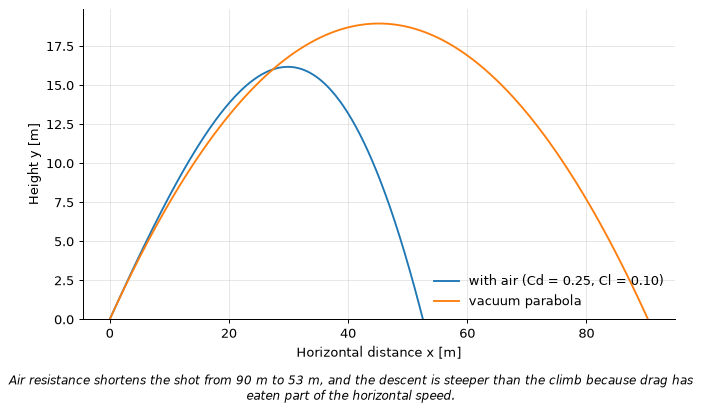

In [3]:
nom = params.nominal(SPEC)
res = bh.run(record=1)                       # every input at its nominal value
vac = vacuum_trajectory(nom["v0"], nom["theta"])
for q in ["range", "max_height", "flight_time"]:
    print(f"{q:12s}: with air {res.qoi(q)[0]:6.2f}   vacuum {vac[q]:6.2f}")
print(f"impact speed: with air {res.impact_speed[0]:6.2f}   vacuum {nom['v0']:6.2f}")

fig, ax = plt.subplots()
bh.plot_trajectories([res.trajectories[0], (vac["x"], vac["y"])],
                     ["with air (Cd = 0.25, Cl = 0.10)", "vacuum parabola"], ax=ax)
bh.show(fig, f"Air resistance shortens the shot from {vac['range']:.0f} m to {res.range[0]:.0f} m, and the "
             "descent is steeper than the climb because drag has eaten part of the horizontal speed.")

### Convergence of the Euler scheme

Explicit Euler is first order: the global error should scale like $\Delta t$, a slope of 1 on a log-log
plot. The reference is RK4 with a very small step. Thanks to vectorisation, every step size runs in
the same simulator call (`dt` can be an array).

reference range 52.5366 m
Euler: error at dt = 0.01 s is 0.037 m, fitted slope 0.99
RK4  : fitted slope 1.80 (limited by the linear interpolation of the impact)


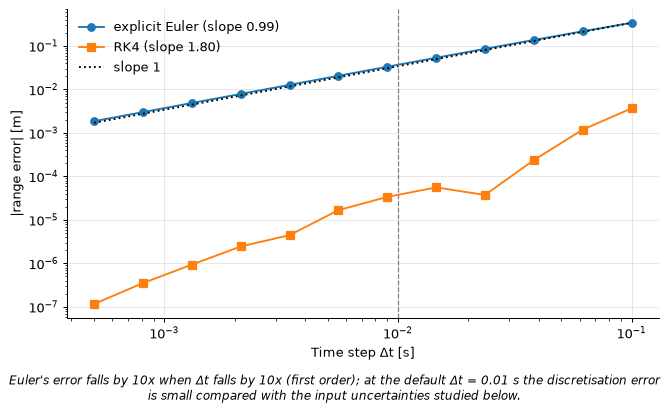

In [4]:
dts = np.logspace(-3.3, -1, 12)
ref = bh.run(dt=2e-4, scheme="rk4").range[0]          # reference solution
err_euler = np.abs(bh.run(dt=dts).range - ref)        # one call, one dt per trajectory
err_rk4 = np.abs(bh.run(dt=dts, scheme="rk4").range - ref)
slope_euler = np.polyfit(np.log(dts), np.log(err_euler), 1)[0]
slope_rk4 = np.polyfit(np.log(dts), np.log(err_rk4), 1)[0]
print(f"reference range {ref:.4f} m")
print(f"Euler: error at dt = 0.01 s is {np.interp(0.01, dts, err_euler):.3f} m, fitted slope {slope_euler:.2f}")
print(f"RK4  : fitted slope {slope_rk4:.2f} (limited by the linear interpolation of the impact)")

fig, ax = plt.subplots()
ax.loglog(dts, err_euler, "o-", label=f"explicit Euler (slope {slope_euler:.2f})")
ax.loglog(dts, err_rk4, "s-", label=f"RK4 (slope {slope_rk4:.2f})")
ax.loglog(dts, err_euler[-1] * dts / dts[-1], "k:", label="slope 1")
ax.axvline(0.01, color="grey", ls="--", lw=1)
ax.set_xlabel("Time step Δt [s]")
ax.set_ylabel("|range error| [m]")
ax.legend()
bh.show(fig, "Euler's error falls by 10x when Δt falls by 10x (first order); at the default Δt = 0.01 s the "
             "discretisation error is small compared with the input uncertainties studied below.")

**Takeaways**
- The simulator is a deterministic function $\text{QoI} = f(v_0, \theta, C_d, C_l, m, w)$. It is cheap
  here, so we can check every UQ method against the truth. Real simulators can take hours per run.
- Euler's error is first order in $\Delta t$. A numerical error is an uncertainty too, but a
  *controllable* one: we can make it negligible by refining $\Delta t$.

**Exercises**
1. Change the reference to Euler with `dt=1e-4` instead of RK4. *Hint:* the slope should not change,
   but the curve flattens at small Δt once the error reaches the reference's own error.
2. Time `bh.run(v0=np.full(10_000, 30.0))` against a Python loop of 100 scalar calls. *Hint:* use
   `with bh.timer(): ...`; per trajectory, the vectorised call is orders of magnitude cheaper.

## 1. Deterministic exploration

**Learning goals**
- Explore the response before adding any uncertainty: always look at the model first.
- See why the best angle is below 45° with drag, and why the optimum is flat.
- See which input combinations matter ($C_d/m$) and how lift and wind act.

best angle with air: 34.0°, max range 53.5 m
range within 1% of the max for θ in [30.0°, 38.5°]


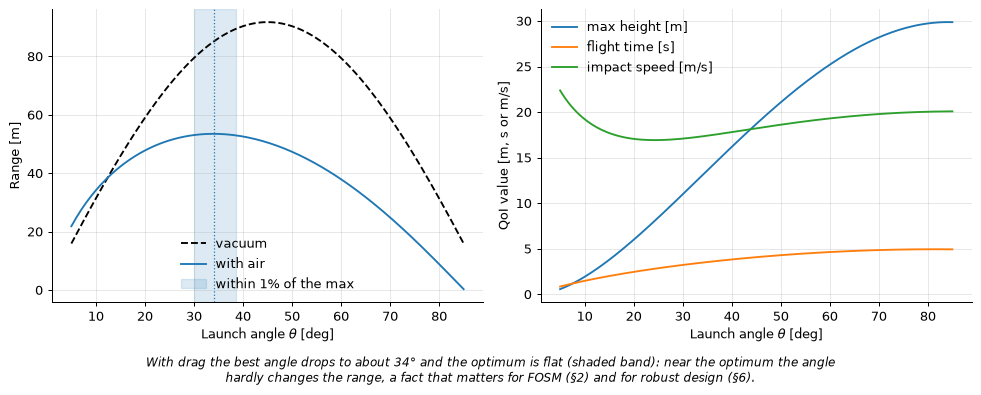

In [5]:
thetas = np.linspace(5, 85, 161)
air = bh.run(theta=thetas)
r_vac = nom["v0"] ** 2 * np.sin(np.radians(2 * thetas)) / G
best = thetas[np.argmax(air.range)]
flat = thetas[air.range >= 0.99 * air.range.max()]
print(f"best angle with air: {best:.1f}°, max range {air.range.max():.1f} m")
print(f"range within 1% of the max for θ in [{flat.min():.1f}°, {flat.max():.1f}°]")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(thetas, r_vac, "k--", label="vacuum")
axes[0].plot(thetas, air.range, label="with air")
axes[0].axvline(best, color="C0", ls=":", lw=1)
axes[0].axvspan(flat.min(), flat.max(), color="C0", alpha=0.15, label="within 1% of the max")
axes[0].set_xlabel(bh.label("theta"))
axes[0].set_ylabel(bh.label("range"))
axes[0].legend()
axes[1].plot(thetas, air.max_height, label="max height [m]")
axes[1].plot(thetas, air.flight_time, label="flight time [s]")
axes[1].plot(thetas, air.impact_speed, label="impact speed [m/s]")
axes[1].set_xlabel(bh.label("theta"))
axes[1].set_ylabel("QoI value [m, s or m/s]")
axes[1].legend()
bh.show(fig, f"With drag the best angle drops to about {best:.0f}° and the optimum is flat (shaded band): "
             "near the optimum the angle hardly changes the range, a fact that matters for FOSM (§2) and "
             "for robust design (§6).")

### Effect of drag, mass, lift and wind

Since only $C_d/m$ enters the equations, range curves for different masses collapse onto one curve when
plotted against $C_d/m$.

range sensitivity to the wind [m per m/s]: {20: 0.81, 40: 1.92, 60: 2.17}


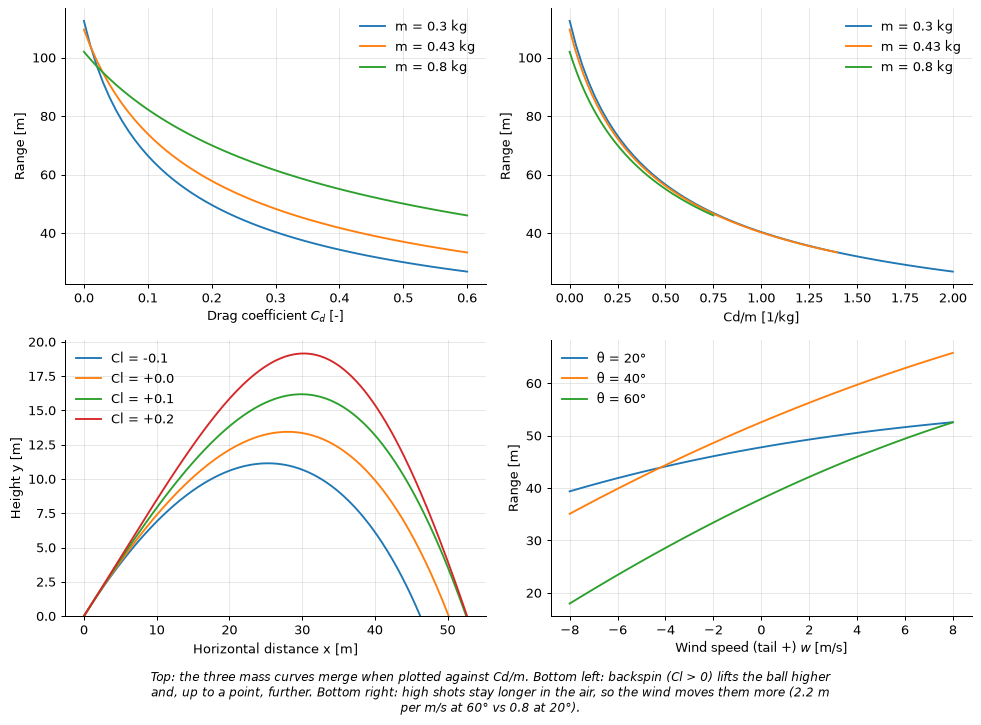

In [6]:
cds = np.linspace(0.0, 0.6, 61)
masses = [0.3, 0.43, 0.8]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for m in masses:
    r = bh.run(cd=cds, mass=m).range
    axes[0, 0].plot(cds, r, label=f"m = {m} kg")
    axes[0, 1].plot(cds / m, r, label=f"m = {m} kg")
axes[0, 0].set_xlabel(bh.label("cd"))
axes[0, 1].set_xlabel("Cd/m [1/kg]")
for ax in axes[0]:
    ax.set_ylabel(bh.label("range"))
    ax.legend()

cls = [-0.1, 0.0, 0.1, 0.2]
lift = bh.run(cl=np.array(cls), record=len(cls))
bh.plot_trajectories(lift.trajectories, [f"Cl = {c:+.1f}" for c in cls], ax=axes[1, 0])

winds = np.linspace(-8, 8, 33)
for th in [20, 40, 60]:
    axes[1, 1].plot(winds, bh.run(theta=th, wind=winds).range, label=f"θ = {th}°")
axes[1, 1].set_xlabel(bh.label("wind"))
axes[1, 1].set_ylabel(bh.label("range"))
axes[1, 1].legend()
slopes = {th: np.polyfit(winds, bh.run(theta=th, wind=winds).range, 1)[0] for th in [20, 40, 60]}
print("range sensitivity to the wind [m per m/s]:", {th: round(float(s), 2) for th, s in slopes.items()})
bh.show(fig, "Top: the three mass curves merge when plotted against Cd/m. Bottom left: backspin (Cl > 0) "
             "lifts the ball higher and, up to a point, further. Bottom right: high shots stay longer in the air, so the wind moves "
             f"them more ({slopes[60]:.1f} m per m/s at 60° vs {slopes[20]:.1f} at 20°).")

**Takeaways**
- With drag, the best angle is below 45° and the range is flat around it.
- Drag and mass act only through $C_d/m$: two parameters, one effect. Data will never separate them (§7).
- Wind sensitivity grows with the flight time, so flatter shots are less exposed to the wind (§6).

**Exercises**
1. Plot the max height against the angle for several $C_d$. Is the angle of maximum height still 90°?
   *Hint:* yes for the height; drag only reduces it.
2. Find the best angle for a headwind of −8 m/s and a tailwind of +8 m/s.
   *Hint:* a tailwind favours higher shots, which spend more time being pushed.

## 2. Uncertainty propagation

**Learning goals**
- Describe input uncertainty with probability laws, including the lognormal convention.
- Write a Monte Carlo loop, then vectorise it; estimate quantiles and a probability of failure with
  confidence intervals.
- Understand the $1/\sqrt n$ convergence and how LHS and Sobol sampling improve it.
- Compare Monte Carlo with the linearised (FOSM) approach and see where FOSM breaks down.

### Input laws

Four inputs are uncertain by default: $v_0$, $\theta$, $C_d$ and the wind $w$, each normal and
independent. **Convention used everywhere:** "mean" and "std" are the moments of the input $X$ itself,
whatever its law. For a lognormal law, the parameters of $\ln X$ are derived from them:

$$\sigma_{\ln}^2 = \ln\!\left(1 + \mathrm{cv}^2\right), \qquad \mu_{\ln} = \ln(\text{mean}) - \tfrac12\sigma_{\ln}^2,
\qquad \mathrm{cv} = \text{std}/\text{mean}.$$

A lognormal law is the natural choice for a positive quantity such as $C_d$: it can never be negative.

lognormal Cd: mean 0.2500, std 0.0300 (requested 0.25, 0.03)
by hand: mu_ln = -1.3934, sigma_ln = 0.1196;  scipy: ln(scale) = -1.3934, s = 0.1196


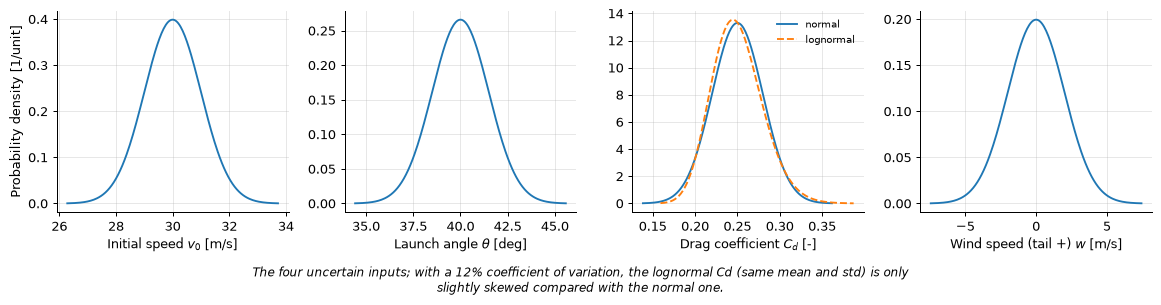

In [7]:
spec_ln = bh.spec_with(cd={"dist": "lognormal"})
d_ln = params.marginal(spec_ln["cd"])
m, s = spec_ln["cd"]["value"], spec_ln["cd"]["std"]
sig_ln = np.sqrt(np.log1p((s / m) ** 2))
mu_ln = np.log(m) - sig_ln**2 / 2
print(f"lognormal Cd: mean {d_ln.mean():.4f}, std {d_ln.std():.4f} (requested {m}, {s})")
print(f"by hand: mu_ln = {mu_ln:.4f}, sigma_ln = {sig_ln:.4f};  scipy: ln(scale) = {np.log(d_ln.kwds['scale']):.4f}, "
      f"s = {d_ln.kwds['s']:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, n in zip(axes, NAMES):
    d = params.marginal(SPEC[n])
    xs = np.linspace(d.ppf(1e-4), d.ppf(1 - 1e-4), 200)
    ax.plot(xs, d.pdf(xs), label="normal")
    if n == "cd":
        xs = np.linspace(d_ln.ppf(1e-4), d_ln.ppf(1 - 1e-4), 200)
        ax.plot(xs, d_ln.pdf(xs), "--", label="lognormal")
        ax.legend(fontsize=8)
    ax.set_xlabel(bh.label(n))
axes[0].set_ylabel("Probability density [1/unit]")
bh.show(fig, "The four uncertain inputs; with a 12% coefficient of variation, the lognormal Cd (same mean "
             "and std) is only slightly skewed compared with the normal one.")

### The Monte Carlo loop

Monte Carlo is the reference method: draw inputs from their laws, run the model, and look at the outputs
as a sample of the output law. The estimate of the mean $\bar y = \frac1n\sum_i f(\mathbf x_i)$ has a
standard error $s_y/\sqrt n$, whatever the dimension. Here is the literal loop:

In [8]:
def mc_loop(spec, names, n, seed=0):
    rng = np.random.default_rng(seed)
    y = np.empty(n)
    for i in range(n):
        x = {nm: spec[nm]["value"] + spec[nm]["std"] * rng.standard_normal() for nm in names}  # normal inputs
        y[i] = bh.run(**x).range[0]  # one simulator run
    return y

t0 = time.perf_counter()
y_loop = mc_loop(SPEC, NAMES, 200)
t_loop = time.perf_counter() - t0
print(f"loop: n = 200, mean {y_loop.mean():.2f} m, std {y_loop.std(ddof=1):.2f} m, "
      f"{1e3 * t_loop / 200:.1f} ms per run")

loop: n = 200, mean 53.16 m, std 5.36 m, 3.9 ms per run


The same thing, vectorised: draw all the samples at once through the unit hypercube (uniform $U$, then
the inverse CDF of each marginal, $x = F^{-1}(u)$), and run them in **one** simulator call. Going
through $[0,1]^d$ is what lets Monte Carlo, LHS, Sobol sequences and sensitivity analysis share one code
path. The result is then checked against `uq_core.propagation.monte_carlo`, which does the same.

In [9]:
n = 4000
t0 = time.perf_counter()
U = np.random.default_rng(0).random((n, len(NAMES)))                      # 1. uniform samples
X = np.column_stack([params.marginal(SPEC[nm]).ppf(U[:, j]) for j, nm in enumerate(NAMES)])  # 2. inverse CDF
y = params.evaluate(SPEC, NAMES, X, "range")                               # 3. one batched simulator call
t_vec = time.perf_counter() - t0
print(f"vectorised: n = {n}, {1e3 * t_vec / n:.3f} ms per run "
      f"({t_loop / 200 / (t_vec / n):.0f}x faster per run than the loop)")

mc = propagation.monte_carlo(SPEC, n=n, sampling="random", seed=0, target=TARGET, tol=TOL, n_traj=60)
print("same samples as uq_core.propagation.monte_carlo:",
      np.allclose(y, mc["qoi"]["range"]["values"], atol=1e-3))

vectorised: n = 4000, 0.010 ms per run (387x faster per run than the loop)
same samples as uq_core.propagation.monte_carlo: True


range: mean 52.58 m, std 5.28 m, 5–95% interval [44.2, 61.5] m
P(miss the target 55 ± 3 m) = 0.625 ± 0.015 (95% CI)
  short: 0.467, long: 0.158


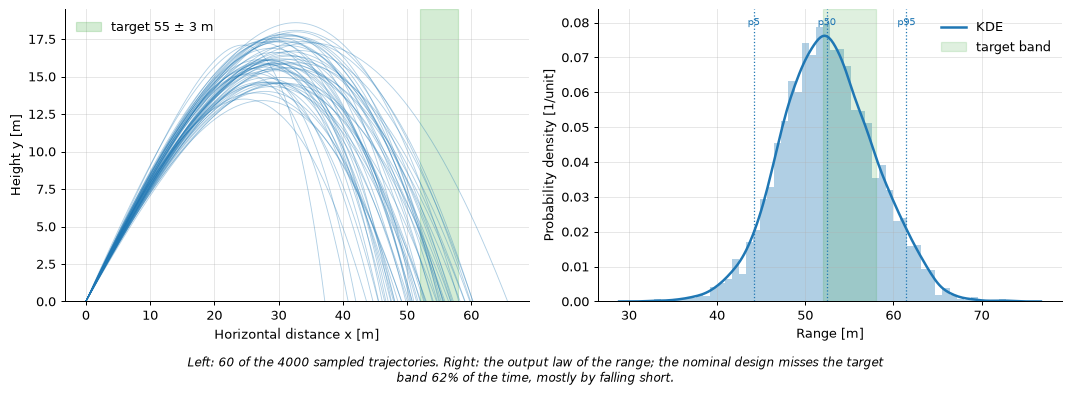

In [10]:
st = propagation.summarize(y)
p_miss = np.mean(np.abs(y - TARGET) > TOL)
half = 1.96 * np.sqrt(p_miss * (1 - p_miss) / n)
print(f"range: mean {st['mean']:.2f} m, std {st['std']:.2f} m, 5–95% interval [{st['p05']:.1f}, {st['p95']:.1f}] m")
print(f"P(miss the target {TARGET:g} ± {TOL:g} m) = {p_miss:.3f} ± {half:.3f} (95% CI)")
print(f"  short: {np.mean(y < TARGET - TOL):.3f}, long: {np.mean(y > TARGET + TOL):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trajs = [np.column_stack([t["x"], t["y"]]) for t in mc["trajectories"]]
bh.plot_spaghetti(trajs, ax=axes[0], target=TARGET, tol=TOL)
bh.plot_hist_kde(y, ax=axes[1], xlabel=bh.label("range"), target=TARGET, tol=TOL)
bh.show(fig, f"Left: 60 of the {n} sampled trajectories. Right: the output law of the range; the nominal "
             f"design misses the target band {100 * p_miss:.0f}% of the time, mostly by falling short.")

### Convergence: $1/\sqrt n$, and better sampling

The running mean and its 95% confidence interval $\bar y \pm 1.96\, s/\sqrt n$ shrink like $1/\sqrt n$:
to gain one digit, you need 100 times more runs. Stratified designs help: **Latin hypercube sampling
(LHS)** forces every marginal to be evenly covered, and **Sobol sequences** (quasi-Monte Carlo) fill the
cube very evenly. To compare them fairly, we repeat each estimator 20 times with different seeds and
measure its root-mean-square error (RMSE) against a reference computed with $2^{16}$ Sobol points.

random  RMSE of the mean: n=16: 1.470  n=64: 0.776  n=256: 0.311  n=1024: 0.142
lhs     RMSE of the mean: n=16: 0.235  n=64: 0.048  n=256: 0.021  n=1024: 0.011
sobol   RMSE of the mean: n=16: 0.285  n=64: 0.054  n=256: 0.009  n=1024: 0.002
at n = 1024, plain MC needs about 155x more runs than LHS and 3723x more than Sobol for the same accuracy


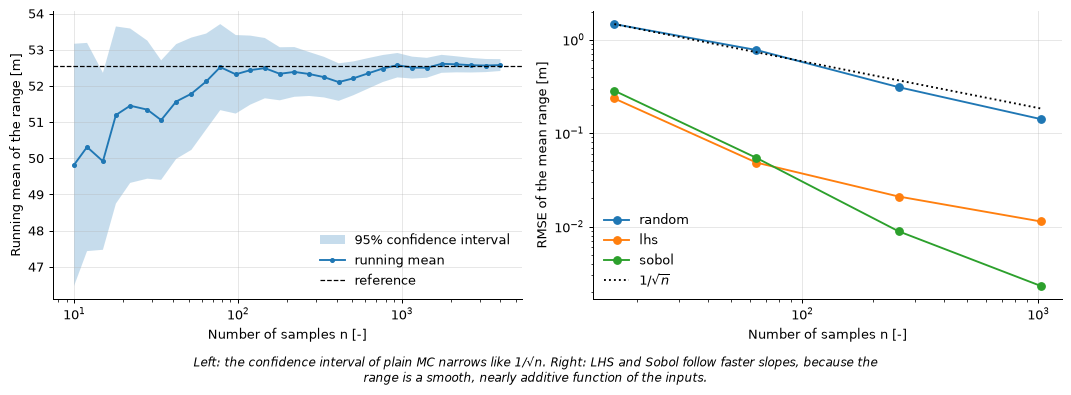

In [11]:
conv = propagation.convergence(y)
ref_mean = bh.qoi_samples(SPEC, 2**16, "sobol", seed=123)[0].mean()

ns, R = [16, 64, 256, 1024], 20
rmse = {}
for method in ["random", "lhs", "sobol"]:
    U_all = np.vstack([doe.unit_design(method, k, len(NAMES), seed) for k in ns for seed in range(R)])
    y_all = params.evaluate(SPEC, NAMES, params.from_unit(SPEC, NAMES, U_all), "range")  # one call
    means = np.add.reduceat(y_all, np.cumsum([0] + [k for k in ns for _ in range(R)])[:-1]) / np.repeat(ns, R)
    rmse[method] = np.sqrt(((means.reshape(len(ns), R) - ref_mean) ** 2).mean(axis=1))
for method, e in rmse.items():
    print(f"{method:7s} RMSE of the mean: " + "  ".join(f"n={k}: {v:.3f}" for k, v in zip(ns, e)))
gain_lhs = (rmse["random"][-1] / rmse["lhs"][-1]) ** 2
gain_sobol = (rmse["random"][-1] / rmse["sobol"][-1]) ** 2
print(f"at n = {ns[-1]}, plain MC needs about {gain_lhs:.0f}x more runs than LHS "
      f"and {gain_sobol:.0f}x more than Sobol for the same accuracy")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bh.plot_convergence(conv, ax=axes[0], exact=ref_mean, ylabel="Running mean of the range [m]")
for method, e in rmse.items():
    axes[1].loglog(ns, e, "o-", label=method)
axes[1].loglog(ns, rmse["random"][0] * np.sqrt(ns[0] / np.array(ns)), "k:", label=r"$1/\sqrt{n}$")
axes[1].set_xlabel("Number of samples n [-]")
axes[1].set_ylabel("RMSE of the mean range [m]")
axes[1].legend()
bh.show(fig, "Left: the confidence interval of plain MC narrows like 1/√n. Right: LHS and Sobol follow "
             "faster slopes, because the range is a smooth, nearly additive function of the inputs.")

### FOSM: the first-order second-moment method

Linearise the model around the mean inputs $\boldsymbol\mu$:

$$\mathbb E[Y] \approx f(\boldsymbol\mu), \qquad
\mathrm{Var}[Y] \approx \sum_i \left(\frac{\partial f}{\partial x_i}\right)^2 \sigma_i^2.$$

It costs only $2d + 1$ runs (centred finite differences), against thousands for Monte Carlo. The fraction
$(\partial_i f\,\sigma_i)^2 / \mathrm{Var}[Y]$ is a first, local, sensitivity measure.

In [12]:
fo = propagation.fosm(SPEC, "range", 0.01)
print(f"FOSM ({2 * len(NAMES) + 1} runs): mean {fo['mean']:.2f} m, std {fo['std']:.2f} m")
print(f"MC   ({n} runs): mean {st['mean']:.2f} m, std {st['std']:.2f} m")
print("FOSM variance shares:", {k: round(v, 3) for k, v in fo["contrib"].items()})

FOSM (9 runs): mean 52.54 m, std 5.19 m
MC   (4000 runs): mean 52.58 m, std 5.28 m
FOSM variance shares: {'v0': 0.152, 'theta': 0.007, 'cd': 0.298, 'wind': 0.543}


At the defaults, FOSM and Monte Carlo agree, because the response is close to linear over ±3σ. FOSM breaks
down when the response curves over the input range. The angle is the textbook case: the default angle (40°)
is close to the flat optimum (§1), so the gradient there is small, but the range drops on both sides
of the optimum. Let us increase the std of θ.

 σ_θ [deg] | MC mean | FOSM mean | MC std | FOSM std | MC skewness
     1.5   |   52.55 |     52.54 |   5.22 |     5.19 |   0.03
     5.0   |   52.01 |     52.54 |   5.42 |     5.37 |  -0.05
    10.0   |   50.18 |     52.54 |   6.66 |     5.95 |  -0.66
    15.0   |   46.99 |     52.54 |  10.00 |     6.80 |  -1.49


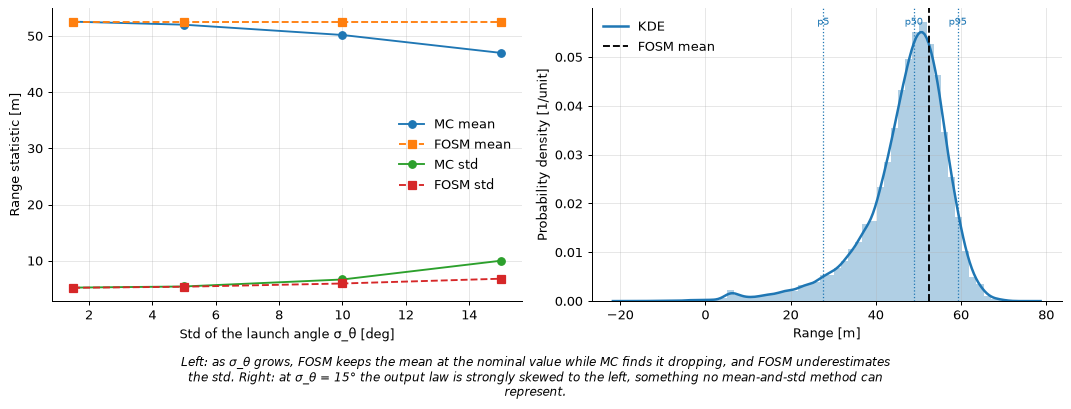

In [13]:
theta_stds = [1.5, 5, 10, 15]
rows = []
for s_th in theta_stds:
    sp = bh.spec_with(theta={"std": s_th})
    y_s = bh.qoi_samples(sp, 2**14, "sobol", seed=0)[0]
    fo_s = propagation.fosm(sp, "range", 0.01)
    rows.append((s_th, y_s.mean(), y_s.std(), fo_s["mean"], fo_s["std"], stats.skew(y_s)))
    if s_th == theta_stds[-1]:
        y_wide = y_s
print(" σ_θ [deg] | MC mean | FOSM mean | MC std | FOSM std | MC skewness")
for r in rows:
    print(f"   {r[0]:5.1f}   | {r[1]:7.2f} | {r[3]:9.2f} | {r[2]:6.2f} | {r[4]:8.2f} | {r[5]:6.2f}")

r = np.array(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(r[:, 0], r[:, 1], "o-", label="MC mean")
axes[0].plot(r[:, 0], r[:, 3], "s--", label="FOSM mean")
axes[0].plot(r[:, 0], r[:, 2], "o-", label="MC std")
axes[0].plot(r[:, 0], r[:, 4], "s--", label="FOSM std")
axes[0].set_xlabel("Std of the launch angle σ_θ [deg]")
axes[0].set_ylabel("Range statistic [m]")
axes[0].legend()
bh.plot_hist_kde(y_wide, ax=axes[1], xlabel=bh.label("range"))
axes[1].axvline(rows[-1][3], color="k", ls="--", label="FOSM mean")
axes[1].legend()
bh.show(fig, f"Left: as σ_θ grows, FOSM keeps the mean at the nominal value while MC finds it dropping, and "
             f"FOSM underestimates the std. Right: at σ_θ = {theta_stds[-1]}° the output law is strongly "
             "skewed to the left, something no mean-and-std method can represent.")

### Joint distribution of two QoIs

All QoIs come out of the same runs, so we also get their joint distribution for free.

correlation(range, max height) = 0.43
correlation(theta, max height) = 0.55


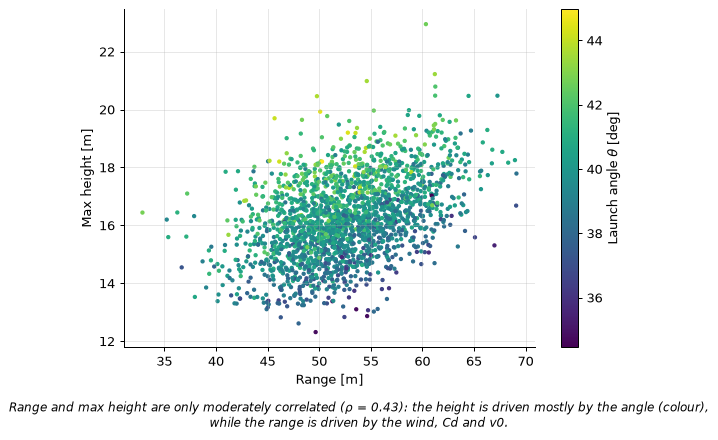

In [14]:
yy = {q: np.asarray(mc["qoi"][q]["values"]) for q in ["range", "max_height"]}
rho = np.corrcoef(yy["range"], yy["max_height"])[0, 1]
theta_s = np.asarray(mc["inputs"]["theta"])
print(f"correlation(range, max height) = {rho:.2f}")
print(f"correlation(theta, max height) = {np.corrcoef(theta_s, yy['max_height'][:len(theta_s)])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(yy["range"][:len(theta_s)], yy["max_height"][:len(theta_s)], c=theta_s, s=6, cmap="viridis")
plt.colorbar(sc, ax=ax, label=bh.label("theta"))
ax.set_xlabel(bh.label("range"))
ax.set_ylabel(bh.label("max_height"))
bh.show(fig, f"Range and max height are only moderately correlated (ρ = {rho:.2f}): the height is driven "
             "mostly by the angle (colour), while the range is driven by the wind, Cd and v0.")

**Takeaways**
- Monte Carlo is simple, dimension-free and the reference, but its error decreases only like $1/\sqrt n$.
  Always report a confidence interval, for probabilities too ($\pm 1.96\sqrt{p(1-p)/n}$).
- LHS and quasi-Monte Carlo (Sobol) reach the same accuracy with far fewer runs on smooth problems.
- FOSM is almost free and fine for small, nearly linear uncertainties, but it misses mean shifts, skewness
  and flat optima.

**Exercises**
1. Make $C_d$ lognormal with std 0.15 (`bh.spec_with(cd={"dist": "lognormal", "std": 0.15})`) and compare
   the range histogram with the normal case. *Hint:* the normal law now produces negative $C_d$ values,
   which are clipped to 0.
2. Increase `n` to 50 000 and check that the confidence interval on $P(\text{miss})$ shrinks by
   $\sqrt{50000/4000} \approx 3.5$.
3. Repeat the RMSE study for the 95% quantile instead of the mean. *Hint:* replace `means` by
   per-block `np.percentile(..., 95)`; the gain of LHS and Sobol is smaller for tail quantities.

## 3. Design of experiments (DoE)

**Learning goals**
- Build a Latin hypercube by hand and check its stratification.
- Measure space filling with the minimum distance (maximin) and the centred discrepancy.
- Compare random, LHS, optimised LHS, Sobol, Halton and full-factorial designs.
- Feel the curse of dimensionality.

When each run is expensive, we choose a small set of points (a *design*) where we will run the simulator,
typically to train a surrogate (§4). Designs live in the unit hypercube $[0,1]^d$ and are mapped to the
physical box afterwards.

### LHS by hand

Split each axis into $n$ equal strata, and give each stratum exactly one point: for each dimension $j$, a
random permutation of the strata plus a uniform jitter inside the stratum,
$u_{ij} = (\pi_j(i) + \xi_{ij})/n$.

In [15]:
def lhs(n, d, seed=0):
    rng = np.random.default_rng(seed)
    U = np.empty((n, d))
    for j in range(d):
        U[:, j] = (rng.permutation(n) + rng.random(n)) / n
    return U

def is_stratified(U):
    n = len(U)
    return bool(np.all(np.sort(np.floor(U * n), axis=0) == np.arange(n)[:, None]))

U_lhs = lhs(16, 2)
print("hand-written LHS stratified:", is_stratified(U_lhs),
      "| uq_core LHS stratified:", is_stratified(doe.unit_design("lhs", 16, 2, seed=0)),
      "| random design stratified:", is_stratified(doe.unit_design("random", 16, 2, seed=0)))

hand-written LHS stratified: True | uq_core LHS stratified: True | random design stratified: False


### Space-filling metrics by hand

- **Minimum distance** (maximin criterion): $\min_{i<j} \|\mathbf u_i - \mathbf u_j\|$, larger is better
  (no two points waste runs by being close).
- **Centred $L_2$ discrepancy** (Hickernell): a measure of how far the empirical distribution of the
  points is from uniform; smaller is better. Its square has a closed form, with $z_{ik} = u_{ik} - \tfrac12$:

$$
CD^2 = \left(\tfrac{13}{12}\right)^d
- \frac{2}{n}\sum_{i}\prod_{k}\left(1 + \tfrac12|z_{ik}| - \tfrac12 z_{ik}^2\right)
+ \frac{1}{n^2}\sum_{i,j}\prod_{k}\left(1 + \tfrac12|z_{ik}| + \tfrac12|z_{jk}| - \tfrac12|u_{ik} - u_{jk}|\right).
$$

In [16]:
def min_distance(U):
    D = np.sqrt(((U[:, None, :] - U[None, :, :]) ** 2).sum(-1))
    return D[np.triu_indices(len(U), 1)].min()

def centred_discrepancy2(U):
    n, d = U.shape
    z = U - 0.5
    t2 = np.prod(1 + 0.5 * np.abs(z) - 0.5 * z**2, axis=1).sum() * 2 / n
    t3 = np.prod(1 + 0.5 * np.abs(z)[:, None] + 0.5 * np.abs(z)[None] - 0.5 * np.abs(U[:, None] - U[None]),
                 axis=2).sum() / n**2
    return (13 / 12) ** d - t2 + t3

ref_m = doe.metrics(U_lhs)  # uq_core: scipy's pdist and qmc.discrepancy (which returns CD²)
print(f"min distance: by hand {min_distance(U_lhs):.6f}, uq_core {ref_m['min_distance']:.6f}")
print(f"CD²         : by hand {centred_discrepancy2(U_lhs):.6f}, uq_core {ref_m['discrepancy']:.6f}")

min distance: by hand 0.098096, uq_core 0.098096
CD²         : by hand 0.003360, uq_core 0.003360


### Six designs side by side

With $n = 16$ points in 2D ($4 \times 4$ for the full factorial). The grid lines mark the 16 strata
of each axis, the ones LHS must fill.

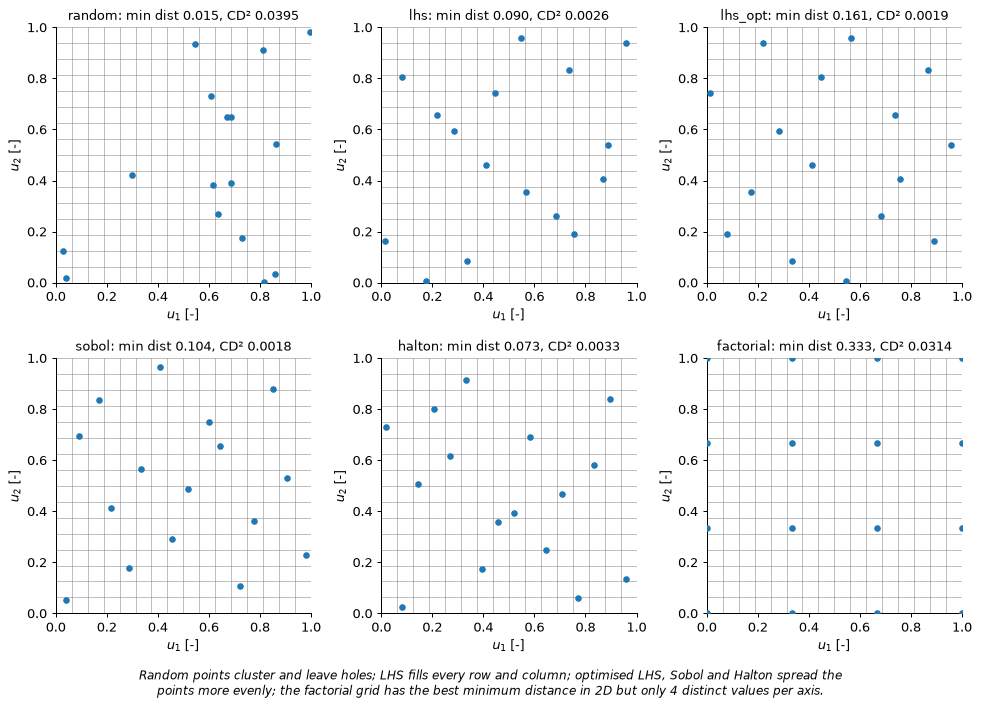

In [17]:
methods = doe.METHODS
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for ax, method in zip(axes.ravel(), methods):
    U2 = doe.unit_design(method, 16, 2, seed=0)
    mt = doe.metrics(U2)
    bh.plot_design_2d(U2, ax, f"{method}: min dist {mt['min_distance']:.3f}, CD² {mt['discrepancy']:.4f}",
                      strata=16)
bh.show(fig, "Random points cluster and leave holes; LHS fills every row and column; optimised LHS, Sobol "
             "and Halton spread the points more evenly; the factorial grid has the best minimum distance in "
             "2D but only 4 distinct values per axis.")

In 4D (our four uncertain inputs), averaged over 20 random seeds, with $n = 32$ points (the full
factorial has only 2 levels per axis there, $2^4 = 16$ points):

In [18]:
d, n_d, seeds = 4, 32, range(20)
print(f"{'method':9s} | n  | min distance (higher = better) | CD² (lower = better)")
table = {}
for method in methods:
    ms = [doe.metrics(doe.unit_design(method, n_d, d, seed)) for seed in seeds]
    table[method] = (np.mean([m["min_distance"] for m in ms]), np.mean([m["discrepancy"] for m in ms]))
    print(f"{method:9s} | {ms[0]['n']:2d} | {table[method][0]:30.3f} | {table[method][1]:.4f}")

method    | n  | min distance (higher = better) | CD² (lower = better)
random    | 32 |                          0.140 | 0.0333
lhs       | 32 |                          0.161 | 0.0076


lhs_opt   | 32 |                          0.250 | 0.0031
sobol     | 32 |                          0.231 | 0.0039
halton    | 32 |                          0.201 | 0.0056
factorial | 16 |                          1.000 | 0.6152


A pair plot shows all 2D projections of a design, here an optimised LHS of 32 points in the physical
box mean ± 3σ, coloured by the simulated range.

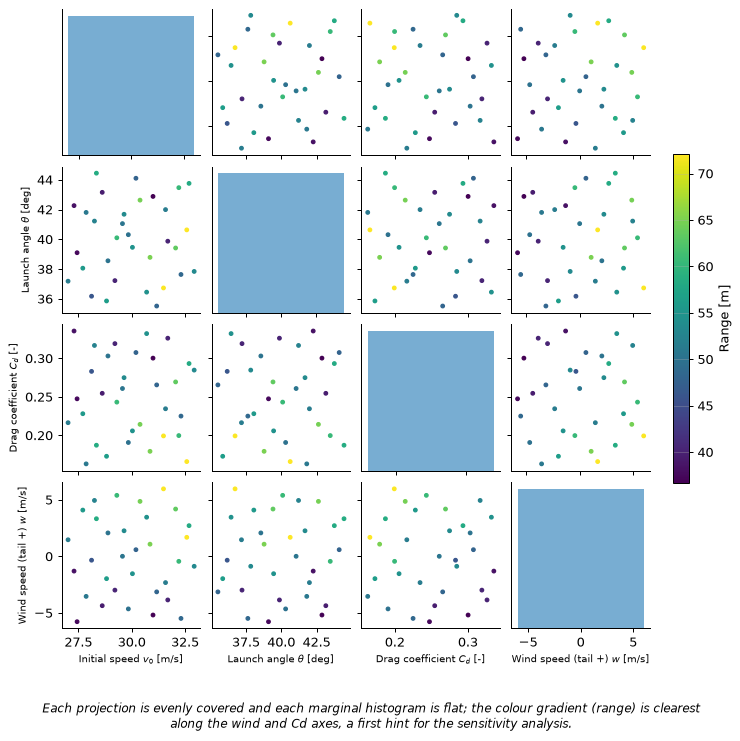

In [19]:
box3 = params.box_from_spec(SPEC, NAMES, k=3)
X_doe = doe.scale(doe.unit_design("lhs_opt", 32, len(NAMES), seed=0), box3)
y_doe = params.evaluate(SPEC, NAMES, X_doe, "range")
fig = bh.plot_pairs(X_doe, NAMES, color=y_doe, bins=8, box=box3, cbar_label=bh.label("range"))
bh.show(fig, "Each projection is evenly covered and each marginal histogram is flat; the colour gradient "
             "(range) is clearest along the wind and Cd axes, a first hint for the sensitivity analysis.")

### The curse of dimensionality

A full factorial with 3 levels needs $3^d$ runs. Space-filling designs do not grow with $d$, but in high
dimension any affordable number of points is sparse: the typical distance to the nearest neighbour grows
quickly with $d$.

3-level factorial size: {1: 3, 2: 9, 3: 27, 4: 81, 5: 243, 6: 729, 7: 2187, 8: 6561, 9: 19683, 10: 59049}


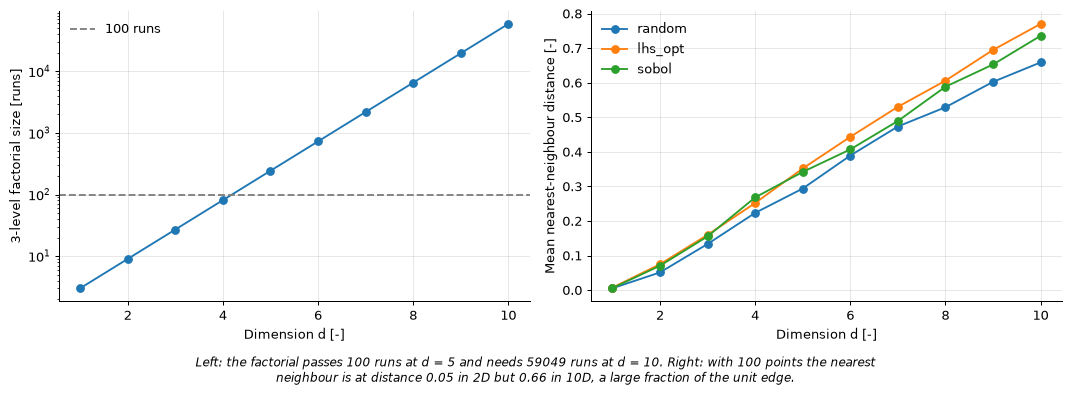

In [20]:
dims = np.arange(1, 11)
nn = {}
for method in ["random", "lhs_opt", "sobol"]:
    vals = []
    for dd in dims:
        U_ = doe.unit_design(method, 100, dd, seed=0)
        D = np.sqrt(((U_[:, None] - U_[None]) ** 2).sum(-1)) + np.eye(100) * 9
        vals.append(D.min(axis=1).mean())
    nn[method] = vals
print("3-level factorial size:", {int(dd): 3 ** int(dd) for dd in dims})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(dims, 3.0**dims, "o-")
axes[0].axhline(100, color="grey", ls="--", label="100 runs")
axes[0].set_xlabel("Dimension d [-]")
axes[0].set_ylabel("3-level factorial size [runs]")
axes[0].legend()
for method, v in nn.items():
    axes[1].plot(dims, v, "o-", label=method)
axes[1].set_xlabel("Dimension d [-]")
axes[1].set_ylabel("Mean nearest-neighbour distance [-]")
axes[1].legend()
bh.show(fig, f"Left: the factorial passes 100 runs at d = 5 and needs {3**10} runs at d = 10. Right: with "
             f"100 points the nearest neighbour is at distance {nn['random'][1]:.2f} in 2D but "
             f"{nn['random'][-1]:.2f} in 10D, a large fraction of the unit edge.")

**Takeaways**
- LHS guarantees even marginals; optimised LHS, Sobol and Halton also improve the joint coverage.
- Minimum distance and discrepancy measure space filling; good designs do well on both.
- Grids explode with dimension; space-filling designs do not, but nothing escapes sparsity in high
  dimension. This is why screening (§5) is done before building surrogates in many dimensions.

**Exercises**
1. Recompute the 4D table with $n = 64$ and $n = 128$. *Hint:* the factorial jumps from 16 points to
   $3^4 = 81$ at $n = 64$ (levels $= \text{round}(n^{1/d})$).
2. Plot the 2D projections of a Halton design in $d = 10$ for dimensions 9 and 10 without scrambling
   (`qmc.Halton(10, scramble=False)`). *Hint:* look for diagonal stripes; this is why `uq_core` scrambles.

## 4. Surrogate models

**Learning goals**
- Fit a Gaussian process (GP) by hand with scikit-learn, and check its mean and variance formulas.
- Compare polynomial, GP, random-forest and neural-network surrogates with $Q^2$, RMSE and parity plots.
- Read learning curves; check whether the GP's ±2σ band is calibrated.
- Understand why a GP slice must pass *through a training point* to show σ = 0.

A surrogate (or metamodel) $\hat f$ is a cheap approximation of the simulator, trained on a design
$\{(\mathbf x_i, y_i)\}$. We judge it on an independent **test set** with

$$Q^2 = 1 - \frac{\sum_k (y_k - \hat f(\mathbf x_k))^2}{\sum_k (y_k - \bar y)^2}, \qquad
\mathrm{RMSE} = \sqrt{\tfrac1{n_t}\textstyle\sum_k (y_k - \hat f(\mathbf x_k))^2}.$$

**Why we use a wide box and a small design.** Within ±3σ of the defaults the range is close to linear, so
with 40 points almost every surrogate reaches $Q^2 \approx 1$:

In [21]:
def quick_q2(kind, k, n_train, seed=0):
    box_ = params.box_from_spec(SPEC, NAMES, k=k)
    X_ = doe.scale(doe.unit_design("lhs_opt", n_train, len(NAMES), seed), box_)
    s_ = surrogate.Surrogate(kind, NAMES, box_, "range", 0.01, SPEC, X_,
                             params.evaluate(SPEC, NAMES, X_, "range")).fit()
    Xt_, yt_ = surrogate.test_set(SPEC, NAMES, box_, "range", 0.01, 500, seed)
    return surrogate.scores(yt_, s_.predict(Xt_))["r2"]

for k, n_tr in [(3, 40), (5, 20)]:
    print(f"box ±{k}σ, n = {n_tr}: Q² " + ", ".join(f"{kd} {quick_q2(kd, k, n_tr):.4f}"
                                                for kd in ["poly1", "poly2", "gp"]))

box ±3σ, n = 40: Q² poly1 0.9781, poly2 0.9996, gp 1.0000


box ±5σ, n = 20: Q² poly1 0.9337, poly2 0.9786, gp 0.9914


So from now on: box mean ± 5σ, and only $n = 20$ training points (an optimised LHS), for the range.

In [22]:
box = params.box_from_spec(SPEC, NAMES, k=5)
n_train = 20
X_train = doe.scale(doe.unit_design("lhs_opt", n_train, len(NAMES), seed=1), box)
y_train = params.evaluate(SPEC, NAMES, X_train, "range")
X_test, y_test = surrogate.test_set(SPEC, NAMES, box, "range", 0.01, 500, seed=0)  # 500 uniform points
print("training box:", {nm: tuple(round(v, 3) for v in b) for nm, b in zip(NAMES, box)})
print(f"training range values: {y_train.min():.1f} to {y_train.max():.1f} m")

training box: {'v0': (25.0, 35.0), 'theta': (32.5, 47.5), 'cd': (0.1, 0.4), 'wind': (-10.0, 10.0)}
training range values: 28.8 to 77.2 m


### A Gaussian process by hand

A GP puts a prior on functions: $f \sim \mathcal{GP}(0, k)$ with the squared-exponential kernel
$k(\mathbf u, \mathbf u') = \sigma_f^2 \exp\!\big(-\tfrac12 \sum_j (u_j - u'_j)^2/\ell_j^2\big)$ on inputs
rescaled to $[0,1]^d$. Conditioning on the training data gives, at a new point $\mathbf u_*$,

$$m(\mathbf u_*) = \mathbf k_*^\top (K + \varepsilon I)^{-1}\mathbf y, \qquad
s^2(\mathbf u_*) = k(\mathbf u_*, \mathbf u_*) - \mathbf k_*^\top (K + \varepsilon I)^{-1}\mathbf k_*,$$

with $K_{ij} = k(\mathbf u_i, \mathbf u_j)$ and $(\mathbf k_*)_i = k(\mathbf u_*, \mathbf u_i)$. The hyperparameters
$\sigma_f, \ell_j$ maximise the marginal likelihood.

**Interpolation, not regression.** The simulator is deterministic: there is no noise to fit. So we use a
tiny jitter $\varepsilon = 10^{-8}$ for numerical stability instead of a fitted noise term (nugget), and
the GP passes exactly through the training points, where $s = 0$. The std we report is the std of the
latent function.

In [23]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

U_train, U_test = doe.to_unit(X_train, box), doe.to_unit(X_test, box)
kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(np.full(len(NAMES), 0.5), (1e-2, 1e2))
gp = GaussianProcessRegressor(kernel, alpha=1e-8, normalize_y=True, n_restarts_optimizer=2, random_state=0)
gp.fit(U_train, y_train)
print("fitted kernel:", gp.kernel_)
mean_sk, std_sk = gp.predict(U_test, return_std=True)

# The same prediction from the formulas above (normalize_y standardises y before conditioning)
ym, ys = y_train.mean(), y_train.std()
K = gp.kernel_(U_train) + 1e-8 * np.eye(n_train)
k_star = gp.kernel_(U_test, U_train)
mean_hand = ym + ys * k_star @ np.linalg.solve(K, (y_train - ym) / ys)
var_hand = ys**2 * (gp.kernel_.diag(U_test) - np.einsum("ij,ji->i", k_star, np.linalg.solve(K, k_star.T)))
print("formulas match sklearn:", np.allclose(mean_hand, mean_sk, atol=1e-6),
      np.allclose(np.sqrt(np.maximum(var_hand, 0)), std_sk, atol=1e-4))

gp_core = surrogate.Surrogate("gp", NAMES, box, "range", 0.01, SPEC, X_train, y_train).fit()
print("matches uq_core's GP surrogate:", np.allclose(gp_core.predict(X_test), mean_sk, atol=1e-6))
print(f"max std at the training points: {gp_core.predict(X_train, return_std=True)[1].max():.1e} m")

fitted kernel: 4.08**2 * RBF(length_scale=[2.41, 3.93, 1.92, 1.58])
formulas match sklearn: True True
matches uq_core's GP surrogate: True
max std at the training points: 1.5e-03 m


### Comparing surrogate families

Linear, quadratic and cubic polynomials (least squares), the GP, a random forest (200 trees) and a
small neural network (MLP, two hidden layers of 64), all trained on the same 20 points.

surrogate                    | test Q² | test RMSE [m]
Linear regression            |  0.9353 |   3.81
Quadratic polynomial         |  0.9945 |   1.11
Cubic polynomial             |  0.9890 |   1.57
Gaussian process (kriging)   |  0.9940 |   1.16
Random forest                |  0.8052 |   6.61
Neural network (MLP)         |  0.9109 |   4.47
polynomial coefficients for d = 4: {'poly1': 5, 'poly2': 15, 'poly3': 35} (vs 20 training points)


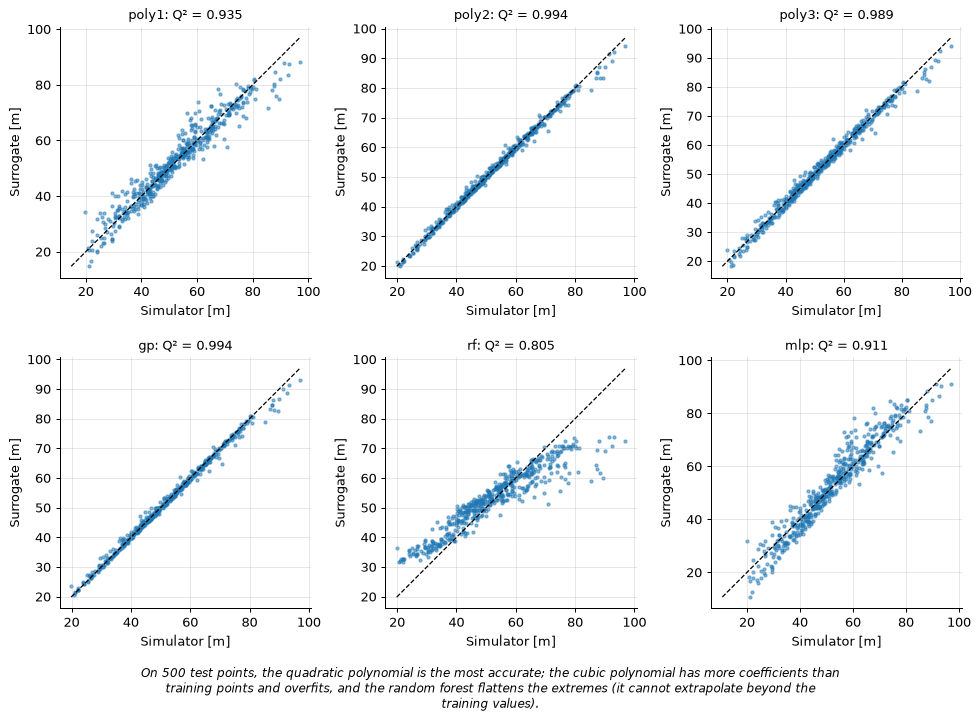

In [24]:
kinds = list(surrogate.KINDS)
models, preds, scores_ = {}, {}, {}
for kind in kinds:
    models[kind] = surrogate.Surrogate(kind, NAMES, box, "range", 0.01, SPEC, X_train, y_train).fit()
    preds[kind] = models[kind].predict(X_test)
    scores_[kind] = surrogate.scores(y_test, preds[kind])
print(f"{'surrogate':28s} | test Q² | test RMSE [m]")
for kind in kinds:
    print(f"{surrogate.KINDS[kind]:28s} | {scores_[kind]['r2']:7.4f} | {scores_[kind]['rmse']:6.2f}")
n_coef = {"poly1": 5, "poly2": 15, "poly3": 35}
print("polynomial coefficients for d = 4:", n_coef, f"(vs {n_train} training points)")

fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for ax, kind in zip(axes.ravel(), kinds):
    bh.plot_parity(y_test, preds[kind], ax=ax, title=f"{kind}: Q² = {scores_[kind]['r2']:.3f}")
best_kind = max(scores_, key=lambda k_: scores_[k_]["r2"])
bh.show(fig, f"On 500 test points, the {surrogate.KINDS[best_kind].lower()} is the most accurate; the cubic "
             "polynomial has more coefficients than training points and overfits, and the random forest "
             "flattens the extremes (it cannot extrapolate beyond the training values).")

### Learning curves

How fast does each surrogate improve with more training points? (Test RMSE on 400 uniform points;
optimised-LHS designs of increasing size.)

poly1 RMSE [m]:   4.102    3.940    3.904    3.854    3.853   (n = [10, 20, 40, 80, 160])
poly2 RMSE [m]:   4.811    2.167    0.904    0.865    0.848   (n = [10, 20, 40, 80, 160])
gp    RMSE [m]:   3.067    1.376    0.309    0.072    0.018   (n = [10, 20, 40, 80, 160])
rf    RMSE [m]:   8.884    7.421    5.101    3.639    3.238   (n = [10, 20, 40, 80, 160])


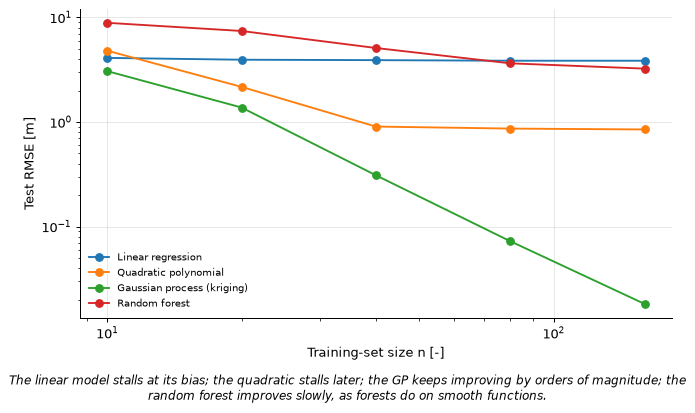

In [25]:
sizes = [10, 20, 40, 80, 160]
lc = surrogate.learning_curve(SPEC, NAMES, box, ["poly1", "poly2", "gp", "rf"], sizes, "lhs_opt", "range")
for kind, c in lc["curves"].items():
    print(f"{kind:5s} RMSE [m]: " + "  ".join(f"{v:7.3f}" for v in c["rmse"]) + f"   (n = {sizes})")

fig, ax = plt.subplots()
bh.plot_learning_curves(lc, ax=ax)
bh.show(fig, "The linear model stalls at its bias; the quadratic stalls later; the GP keeps improving "
             "by orders of magnitude; the random forest improves slowly, as forests do on smooth functions.")

### Is the GP's uncertainty calibrated?

The GP gives an error bar for free. If it were perfectly calibrated (and the errors Gaussian), about 95%
of the test errors would fall inside ±2σ, and the standardised errors $(y - m)/s$ would follow
$\mathcal N(0, 1)$. The σ comes from a model whose hyperparameters (here the length scales) were
estimated from the same 20 points, and that estimation uncertainty is ignored: expect σ to be too small
when data are scarce.

fraction of test errors within ±2σ: 65.0% (95.4% if calibrated)
std of the standardised errors: 2.36 (1 if calibrated)


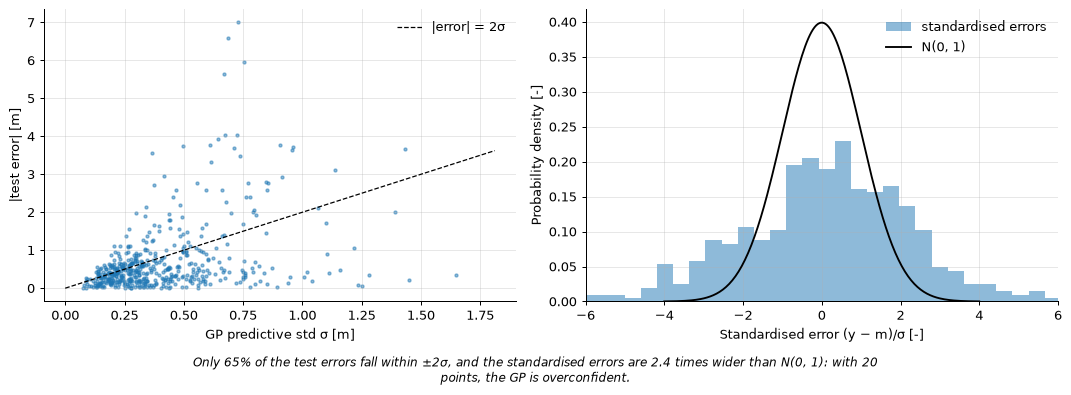

In [26]:
m_gp, s_gp = models["gp"].predict(X_test, return_std=True)
z = (y_test - m_gp) / s_gp
inside = np.mean(np.abs(y_test - m_gp) < 2 * s_gp)
print(f"fraction of test errors within ±2σ: {inside:.1%} (95.4% if calibrated)")
print(f"std of the standardised errors: {z.std():.2f} (1 if calibrated)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(s_gp, np.abs(y_test - m_gp), s=6, alpha=0.5)
lim = 1.1 * s_gp.max()
axes[0].plot([0, lim], [0, 2 * lim], "k--", lw=1, label="|error| = 2σ")
axes[0].set_xlabel("GP predictive std σ [m]")
axes[0].set_ylabel("|test error| [m]")
axes[0].legend()
axes[1].hist(z, bins=40, density=True, alpha=0.5, label="standardised errors")
zz = np.linspace(-4, 4, 200)
axes[1].plot(zz, stats.norm.pdf(zz), "k", label="N(0, 1)")
axes[1].set_xlim(-6, 6)
axes[1].set_xlabel("Standardised error (y − m)/σ [-]")
axes[1].set_ylabel("Probability density [-]")
axes[1].legend()
bh.show(fig, f"Only {inside:.0%} of the test errors fall within ±2σ, and the standardised errors are "
             f"{z.std():.1f} times wider than N(0, 1): with 20 points, the GP is overconfident.")

### Slices: always pass through a training point

A 1D slice varies one input and keeps the others fixed. In 4D, a slice through the nominal values passes
near **no** training point, so the GP's σ never drops to zero along it, and the projected training points
look as if the GP missed them. A slice through a training point shows the interpolation: σ = 0 there.

slice anchor (training point 2): {'v0': 29.616, 'theta': 36.119, 'cd': 0.236, 'wind': -3.103}
min σ along the nominal slice: 0.130 m; along the slice through the point: 1.5e-03 m


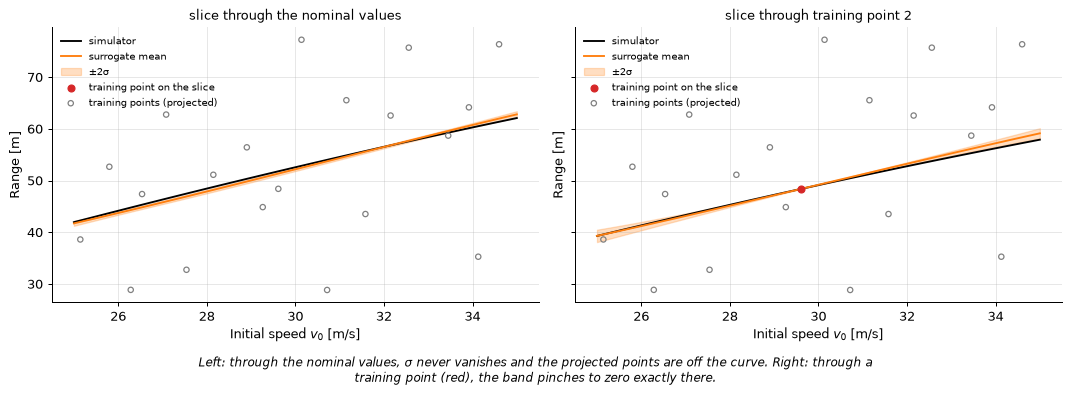

In [27]:
param = "v0"
i_near = np.argmin(np.linalg.norm(doe.to_unit(X_train, box) - 0.5, axis=1))  # training point nearest the centre
anchor = dict(zip(NAMES, X_train[i_near]))
sl_nom = surrogate.slice_1d(models["gp"], param)
sl_pt = surrogate.slice_1d(models["gp"], param, anchor=anchor)
print(f"slice anchor (training point {i_near}):", {k_: round(float(v), 3) for k_, v in anchor.items()})
print(f"min σ along the nominal slice: {min(sl_nom['std']):.3f} m; along the slice through the point: "
      f"{min(sl_pt['std']):.1e} m")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bh.plot_slice(sl_nom, param, ax=axes[0], title="slice through the nominal values")
bh.plot_slice(sl_pt, param, ax=axes[1], title=f"slice through training point {i_near}")
bh.show(fig, "Left: through the nominal values, σ never vanishes and the projected points are off the "
             "curve. Right: through a training point (red), the band pinches to zero exactly there.")

### Speed-up

Our simulator is already vectorised and cheap, so the speed-up is modest here. With a simulator taking
one minute per run, the surrogate's cost would be negligible next to the training runs.

In [28]:
X_big = doe.scale(np.random.default_rng(5).random((20_000, len(NAMES))), box)
t0 = time.perf_counter()
params.evaluate(SPEC, NAMES, X_big, "range")
t_sim = time.perf_counter() - t0
print(f"simulator : {1e6 * t_sim / len(X_big):8.2f} µs per point")
for kind in ["poly2", "gp", "rf", "mlp"]:
    t0 = time.perf_counter()
    models[kind].predict(X_big)
    t_k = time.perf_counter() - t0
    print(f"{kind:10s}: {1e6 * t_k / len(X_big):8.2f} µs per point ({t_sim / t_k:6.1f}x faster)")

simulator :     8.99 µs per point
poly2     :     0.09 µs per point ( 100.7x faster)
gp        :     0.31 µs per point (  28.6x faster)
rf        :     4.16 µs per point (   2.2x faster)
mlp       :     1.66 µs per point (   5.4x faster)


**Takeaways**
- Always judge a surrogate on independent test data ($Q^2$, RMSE, parity plot), never on its training
  points: an interpolating GP or an overfitted cubic is perfect there.
- On this smooth response, the quadratic polynomial and the GP are the best with 20 points, and the GP
  keeps improving with more data (learning curves). Forests and neural networks need far more data; they
  pay off for rough or high-dimensional responses.
- The GP σ is an indicator of where it may be wrong, not a calibrated error bar: check its coverage on
  test data.
- The GP σ is zero at the training points; in more than 2 dimensions, slice through a training point to see it.

**Exercises**
1. Change the QoI to `"max_height"` and rerun the comparison. *Hint:* the max height depends strongly and
   nonlinearly on θ; the linear model suffers more.
2. Train on the k = 3 box instead and check that all surrogates reach $Q^2 \approx 1$ (lesson: a
   too-easy benchmark tells you nothing).
3. Fit the GP with a fitted nugget (`make_estimator("gp", 4, nugget=True)`) and see how σ at the
   training points changes.

## 5. Sensitivity analysis (SA)

**Learning goals**
- Go from local to global: one-at-a-time (tornado) → Morris screening → Sobol indices.
- Implement the Saltelli/Jansen estimators of the Sobol indices and check them against `uq_core`.
- Compare their cost, run Sobol on a surrogate, and look at convergence and interactions.

All methods take a model function `fn(X)` whose columns are the uncertain inputs. It can be the simulator
or a surrogate.

tornado swings [m]: {'wind': 12.6, 'cd': 9.45, 'v0': 6.64, 'theta': 1.47} (9 runs)
Morris mu*        : {'wind': 15.17, 'cd': 11.08, 'v0': 8.61, 'theta': 1.59} (100 runs)


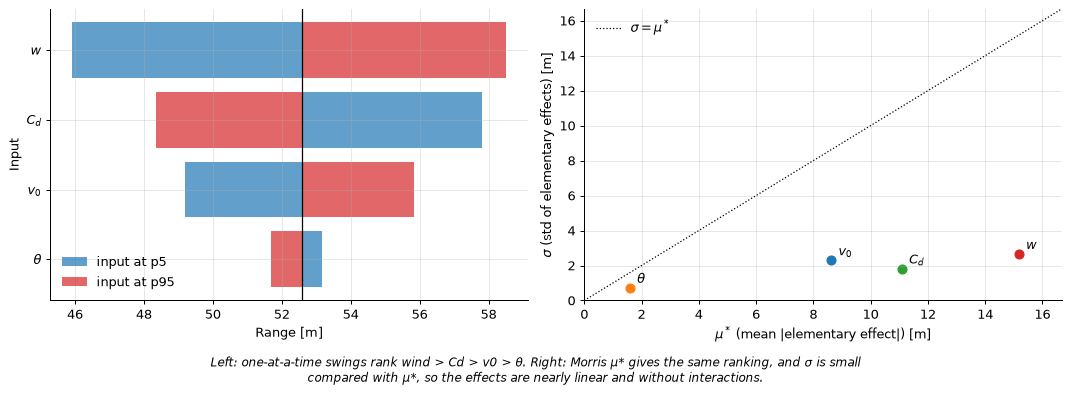

In [29]:
fn_sim = lambda X: params.evaluate(SPEC, NAMES, X, "range")  # noqa: E731

oat = sensitivity.oat(fn_sim, SPEC, NAMES)          # each input from its 5% to its 95% quantile
mo = sensitivity.morris(fn_sim, SPEC, NAMES, r=20, seed=0)
print("tornado swings [m]:", {r_["name"]: round(r_["swing"], 2) for r_ in oat["rows"]}, f"({oat['cost']['evaluations']} runs)")
print("Morris mu*        :", {r_["name"]: round(r_["mu_star"], 2) for r_ in sorted(mo["rows"], key=lambda r_: -r_["mu_star"])},
      f"({mo['cost']['evaluations']} runs)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bh.plot_tornado(oat, ax=axes[0], xlabel=bh.label("range"))
bh.plot_morris(mo, ax=axes[1])
bh.show(fig, "Left: one-at-a-time swings rank wind > Cd > v0 > θ. Right: Morris μ* gives the same ranking, "
             "and σ is small compared with μ*, so the effects are nearly linear and without interactions.")

**Morris** moves one input at a time along $r$ random trajectories on a grid in probability space and
records the *elementary effects* $EE_i = [f(\mathbf x + \Delta \mathbf e_i) - f(\mathbf x)]/\Delta$.
The mean of $|EE_i|$ ($\mu^*$) ranks importance; their std ($\sigma$) flags nonlinearity or interactions.
It costs $r(d+1)$ runs.

### Sobol indices by hand

Variance-based indices split $\mathrm{Var}[Y]$ among the inputs:

$$S_i = \frac{\mathrm{Var}\big[\mathbb E[Y \mid X_i]\big]}{\mathrm{Var}[Y]} \;\;\text{(first order)},\qquad
S_{T_i} = \frac{\mathbb E\big[\mathrm{Var}[Y \mid \mathbf X_{\sim i}]\big]}{\mathrm{Var}[Y]} \;\;\text{(total)}.$$

$S_i$ is the share of variance due to $X_i$ alone; $S_{T_i}$ adds all its interactions. With two independent
sample matrices $A, B$ ($N \times d$) and $A_B^{(i)}$ = $A$ with its column $i$ taken from $B$, the
Saltelli (2010) and Jansen estimators are

$$\hat V_i = \frac1N \sum_k f(B)_k \big(f(A_B^{(i)})_k - f(A)_k\big), \qquad
\hat E_{\sim i} = \frac1{2N} \sum_k \big(f(A)_k - f(A_B^{(i)})_k\big)^2,$$

$S_i = \hat V_i / \hat V$, $S_{T_i} = \hat E_{\sim i}/\hat V$. Cost: $N(d+2)$ runs. Two practical rules:
**centre the outputs** first (subtract the mean; it changes nothing in theory but removes a huge source
of estimator variance), and use base sizes $N = 2^m$ with a Sobol sequence.

In [30]:
def sobol_indices(fn, spec, names, N, seed=0, centre=True, sampler="sobol"):
    d = len(names)
    if sampler == "sobol":
        U = qmc.Sobol(2 * d, scramble=True, rng=np.random.default_rng(seed)).random(N)
    else:  # plain Monte Carlo
        U = np.random.default_rng(seed).random((N, 2 * d))
    A, B = U[:, :d], U[:, d:]
    ABs = []
    for i in range(d):
        AB = A.copy()
        AB[:, i] = B[:, i]
        ABs.append(AB)
    y = fn(params.from_unit(spec, names, np.vstack([A, B] + ABs))).reshape(d + 2, N)  # one batched call
    if centre:
        y = y - y[:2].mean()
    fA, fB, fAB = y[0], y[1], y[2:]
    V = np.var(np.r_[fA, fB])
    S1 = np.mean(fB * (fAB - fA), axis=1) / V     # Saltelli 2010
    ST = 0.5 * np.mean((fA - fAB) ** 2, axis=1) / V  # Jansen
    return S1, ST

N = 2**12
S1, ST = sobol_indices(fn_sim, SPEC, NAMES, N)
sob_sim = sensitivity.sobol(fn_sim, SPEC, NAMES, n_base=N, seed=0, n_boot=200)
print("matches uq_core.sensitivity.sobol:",
      np.allclose(S1, [r_["S1"] for r_ in sob_sim["rows"]]), np.allclose(ST, [r_["ST"] for r_ in sob_sim["rows"]]))
for nm, a, b in zip(NAMES, S1, ST):
    print(f"  {nm:5s} S1 = {a:.3f}   ST = {b:.3f}")
print(f"sum of S1 = {S1.sum():.3f}  ({sob_sim['cost']['evaluations']} simulator runs)")

matches uq_core.sensitivity.sobol: True True
  v0    S1 = 0.152   ST = 0.155
  theta S1 = 0.008   ST = 0.008
  cd    S1 = 0.303   ST = 0.305
  wind  S1 = 0.533   ST = 0.536
sum of S1 = 0.996  (24576 simulator runs)


### Sobol on a surrogate

$N(d+2)$ runs is a lot for an expensive simulator, but nothing for a surrogate. We train a GP on 40
points of an optimised LHS in the ±5σ box, then estimate the indices on the GP.

    input | S1 simulator | S1 GP  | ST simulator | ST GP
    v0    |        0.152 |  0.149 |        0.155 |  0.153
    theta |        0.008 |  0.008 |        0.008 |  0.008
    cd    |        0.303 |  0.304 |        0.305 |  0.306
    wind  |        0.533 |  0.535 |        0.536 |  0.537


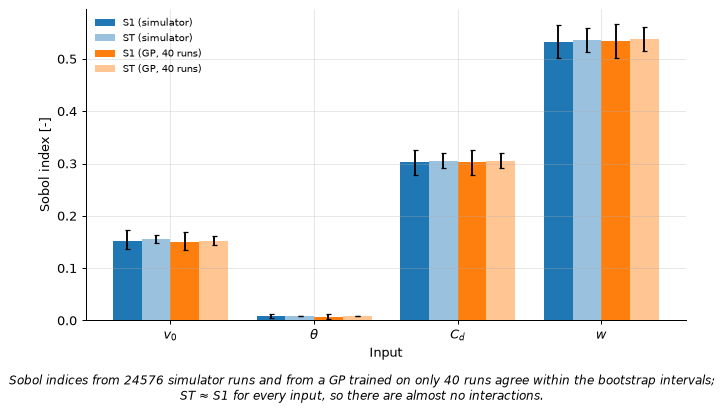

In [31]:
X_sa = doe.scale(doe.unit_design("lhs_opt", 40, len(NAMES), seed=2), box)
gp_sa = surrogate.Surrogate("gp", NAMES, box, "range", 0.01, SPEC, X_sa, fn_sim(X_sa)).fit()
sob_gp = sensitivity.sobol(gp_sa.predict, SPEC, NAMES, n_base=N, seed=0, n_boot=200)
print("    input | S1 simulator | S1 GP  | ST simulator | ST GP")
for a, b in zip(sob_sim["rows"], sob_gp["rows"]):
    print(f"    {a['name']:5s} | {a['S1']:12.3f} | {b['S1']:6.3f} | {a['ST']:12.3f} | {b['ST']:6.3f}")

fig, ax = plt.subplots()
bh.plot_sobol({"simulator": sob_sim, "GP, 40 runs": sob_gp}, ax=ax)
bh.show(fig, f"Sobol indices from {sob_sim['cost']['evaluations']} simulator runs and from a GP trained on "
             "only 40 runs agree within the bootstrap intervals; ST ≈ S1 for every input, so there are "
             "almost no interactions.")

In [32]:
cost = {"FOSM / local derivatives": 2 * len(NAMES) + 1,
        "one-at-a-time (tornado)": oat["cost"]["evaluations"],
        "Morris (r = 20)": mo["cost"]["evaluations"],
        f"Sobol on the simulator (N = {N})": sob_sim["cost"]["evaluations"],
        "Sobol on a GP (training runs)": len(X_sa)}
print(f"{'method':36s} | runs   | if one run took 1 min")
for k_, v in cost.items():
    print(f"{k_:36s} | {v:6d} | {v / 60:8.1f} h")

method                               | runs   | if one run took 1 min
FOSM / local derivatives             |      9 |      0.1 h
one-at-a-time (tornado)              |      9 |      0.1 h
Morris (r = 20)                      |    100 |      1.7 h
Sobol on the simulator (N = 4096)    |  24576 |    409.6 h
Sobol on a GP (training runs)        |     40 |      0.7 h


### Convergence with N, and the effect of centring

How large must $N$ be? We repeat the estimate for $N = 2^5 \dots 2^{12}$. Then, at $N = 256$, we compare
the spread of the estimates over 30 seeds with and without centring the outputs, for plain random
sampling and for a Sobol sequence.

std of S1 over 30 seeds at N = 256:
  v0    random sampling: centred 0.032, raw 0.288 (9x) | Sobol sequence: centred 0.012, raw 0.016 (1.3x)
  theta random sampling: centred 0.010, raw 0.076 (8x) | Sobol sequence: centred 0.002, raw 0.005 (2.0x)
  cd    random sampling: centred 0.050, raw 0.511 (10x) | Sobol sequence: centred 0.009, raw 0.020 (2.1x)
  wind  random sampling: centred 0.080, raw 0.641 (8x) | Sobol sequence: centred 0.017, raw 0.028 (1.6x)


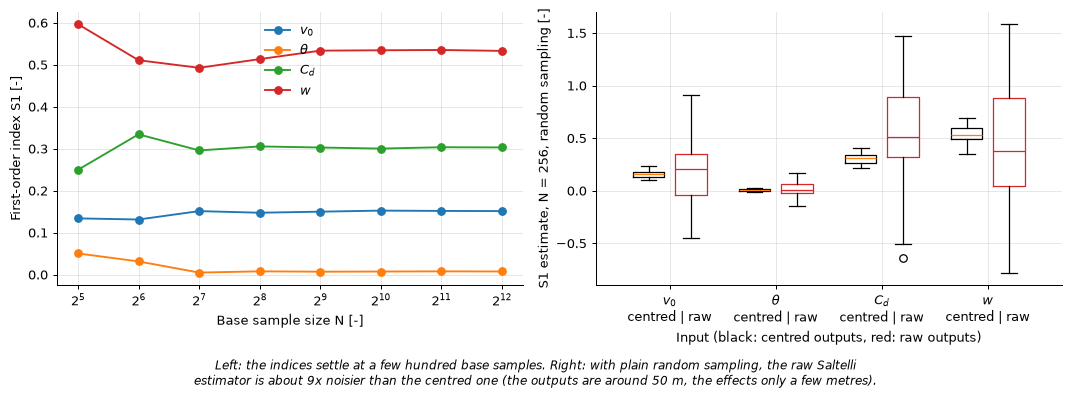

In [33]:
Ns = 2 ** np.arange(5, 13)
conv_s1 = np.array([sobol_indices(fn_sim, SPEC, NAMES, int(Nk), seed=0)[0] for Nk in Ns])

reps = {(c, smp): np.array([sobol_indices(fn_sim, SPEC, NAMES, 256, seed=s, centre=c, sampler=smp)[0]
                            for s in range(30)])
        for c in (True, False) for smp in ("random", "sobol")}
gain = {smp: reps[False, smp].std(0) / reps[True, smp].std(0) for smp in ("random", "sobol")}
print("std of S1 over 30 seeds at N = 256:")
for j, nm in enumerate(NAMES):
    print(f"  {nm:5s} random sampling: centred {reps[True, 'random'][:, j].std():.3f}, raw "
          f"{reps[False, 'random'][:, j].std():.3f} ({gain['random'][j]:.0f}x) | Sobol sequence: centred "
          f"{reps[True, 'sobol'][:, j].std():.3f}, raw {reps[False, 'sobol'][:, j].std():.3f} ({gain['sobol'][j]:.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, nm in enumerate(NAMES):
    axes[0].semilogx(Ns, conv_s1[:, j], "o-", base=2, label=bh.SYMBOLS[nm])
axes[0].set_xlabel("Base sample size N [-]")
axes[0].set_ylabel("First-order index S1 [-]")
axes[0].legend()
pos = np.arange(len(NAMES))
axes[1].boxplot([reps[True, "random"][:, j] for j in pos], positions=pos - 0.2, widths=0.3)
axes[1].boxplot([reps[False, "random"][:, j] for j in pos], positions=pos + 0.2, widths=0.3,
                boxprops={"color": "C3"}, medianprops={"color": "C3"})
axes[1].set_xticks(pos, [f"{bh.SYMBOLS[nm]}\ncentred | raw" for nm in NAMES])
axes[1].set_xlabel("Input (black: centred outputs, red: raw outputs)")
axes[1].set_ylabel("S1 estimate, N = 256, random sampling [-]")
bh.show(fig, "Left: the indices settle at a few hundred base samples. Right: with plain random sampling, "
             f"the raw Saltelli estimator is about {gain['random'].mean():.0f}x noisier than the centred one "
             "(the outputs are around 50 m, the effects only a few metres).")

### Interactions

$\sum_i S_i = 1$ for an additive model; $1 - \sum_i S_i$ is the share of variance due to interactions,
and $S_{T_i} - S_i$ is the share of the interactions involving $X_i$. Even with a very uncertain launch
angle, which makes the response strongly nonlinear in θ (§2), the model stays nearly additive:

In [34]:
for s_th in [1.5, 15]:
    sp = bh.spec_with(theta={"std": s_th})
    f_ = lambda X, sp=sp: params.evaluate(sp, NAMES, X, "range")  # noqa: E731
    s1_, st_ = sobol_indices(f_, sp, NAMES, 2**12)
    print(f"σ_θ = {s_th:4}°: sum S1 = {s1_.sum():.3f};  ST − S1 = "
          + ", ".join(f"{nm} {b - a:.3f}" for nm, a, b in zip(NAMES, s1_, st_)))

σ_θ =  1.5°: sum S1 = 0.996;  ST − S1 = v0 0.004, theta 0.000, cd 0.002, wind 0.002


σ_θ =   15°: sum S1 = 0.981;  ST − S1 = v0 0.004, theta 0.019, cd 0.003, wind 0.015


**Takeaways**
- Default ranking for the range: wind > Cd > v0 > θ, with almost no interactions ($\sum S_1 \approx 1$).
  θ hardly matters because the default angle is close to the flat optimum.
- Tornado and Morris are cheap screening tools; Sobol indices are the global, variance-based reference.
  With a surrogate, Sobol costs only the training runs.
- Centre the outputs (a ~10x smaller estimator std with random sampling; a Sobol sequence already
  cancels most of that error) and use $N = 2^m$ Sobol samples; always show bootstrap confidence intervals.

**Exercises**
1. Make the lift coefficient uncertain (`bh.spec_with(cl={"uncertain": True})`) and recompute the indices.
   *Hint:* `NAMES` must be recomputed with `params.uncertain_names`.
2. Compute the indices for the max height. *Hint:* now θ and v0 dominate and the wind hardly matters.
3. Redo the surrogate comparison with a GP trained on 15 points. When does the ranking break down?

## 6. Robust optimisation

**Learning goals**
- Formulate design under uncertainty: deterministic, mean–variance and chance-constraint objectives.
- Use common random numbers (CRN) to get a smooth objective landscape.
- Re-check optima on the true simulator with fresh samples; allocate tolerances.

**Problem.** The shooter chooses the *means* $\boldsymbol\mu = (\mu_{v_0}, \mu_\theta)$ of the launch speed
and angle. The actual shot is $v_0 = \mu_{v_0} + e_{v_0}$, $\theta = \mu_\theta + e_\theta$ (execution
tolerances), and $C_d$ and the wind are **nuisance parameters** the shooter cannot control. Goal: a range
of 55 ± 3 m. Three objectives:

$$J_\text{det} = \big(f(\boldsymbol\mu) - T\big)^2, \qquad
J_\text{mv} = \big(\mathbb E[f] - T\big)^2 + \lambda\, \mathrm{Var}[f], \qquad
J_\text{cc} = 1 - P\big(|f - T| \le \text{tol}\big).$$

### Common random numbers

Each objective is estimated by Monte Carlo at each candidate design. If every design gets fresh samples,
the landscape is noisy and the optimiser chases noise. With **common random numbers**, the same
deviations $e$ are reused for every design: the noise becomes a fixed, smooth bias, and comparisons
between designs are fair.

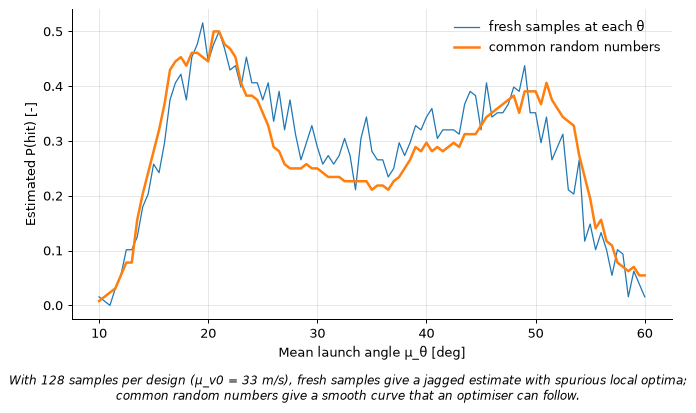

In [35]:
def p_hit_curve(theta_grid, v0, n, crn, seed=0):
    rng = np.random.default_rng(seed)
    stds = np.array([SPEC[nm]["std"] for nm in NAMES])
    E_common = rng.standard_normal((n, len(NAMES))) * stds
    X = []
    for th in theta_grid:
        E = E_common if crn else rng.standard_normal((n, len(NAMES))) * stds
        centre = np.array([v0, th, SPEC["cd"]["value"], SPEC["wind"]["value"]])
        X.append(centre + E)
    y_ = params.evaluate(SPEC, NAMES, np.vstack(X), "range").reshape(len(theta_grid), n)
    return (np.abs(y_ - TARGET) <= TOL).mean(axis=1)

th_grid = np.linspace(10, 60, 101)
fig, ax = plt.subplots()
ax.plot(th_grid, p_hit_curve(th_grid, 33, 128, crn=False), lw=1, label="fresh samples at each θ")
ax.plot(th_grid, p_hit_curve(th_grid, 33, 128, crn=True), lw=2, label="common random numbers")
ax.set_xlabel("Mean launch angle μ_θ [deg]")
ax.set_ylabel("Estimated P(hit) [-]")
ax.legend()
bh.show(fig, "With 128 samples per design (μ_v0 = 33 m/s), fresh samples give a jagged estimate with "
             "spurious local optima; common random numbers give a smooth curve that an optimiser can follow.")

### The three optima

`uq_core.robust.optimize` evaluates the three objectives on a 31 × 31 grid of designs with CRN (256
samples each), then refines each optimum with Nelder–Mead. To make the 250 000 evaluations cheap, it
uses a GP surrogate of the range over (v0, θ, Cd, wind), trained on 200 runs. Each optimum is then
**re-checked on the true simulator with 4000 fresh samples**.

In [36]:
bounds = [(20.0, 45.0), (10.0, 60.0)]
with bh.timer("robust optimisation"):
    rob = robust.optimize(SPEC, ["v0", "theta"], bounds, qoi="range", target=TARGET, tol=TOL, lam=1.0,
                          n_mc=256, grid=31, use_surrogate=True, n_train=200, seed=0)
print(f"surrogate test Q² = {rob['surrogate']['test']['r2']:.4f}, model calls on the surrogate: {rob['model_calls']}")
print(f"{'objective':14s} | μ_v0 [m/s] | μ_θ [deg] | P(hit) CRN, surrogate | P(hit) simulator, fresh (95% CI)")
for kind, o in rob["optima"].items():
    p = o["validation"]["p_hit"]
    h = 1.96 * np.sqrt(p * (1 - p) / 4000)
    print(f"{kind:14s} | {o['x']['v0']:10.2f} | {o['x']['theta']:9.2f} | {o['p_hit']:21.3f} | "
          f"{p:.3f} ± {h:.3f}")

robust optimisation: 1.73 s
surrogate test Q² = 0.9998, model calls on the surrogate: 343866
objective      | μ_v0 [m/s] | μ_θ [deg] | P(hit) CRN, surrogate | P(hit) simulator, fresh (95% CI)
deterministic  |      31.13 |     39.51 |                 0.422 | 0.414 ± 0.015
mean_var       |      32.74 |     20.36 |                 0.484 | 0.484 ± 0.015
chance         |      34.59 |     17.31 |                 0.500 | 0.468 ± 0.015


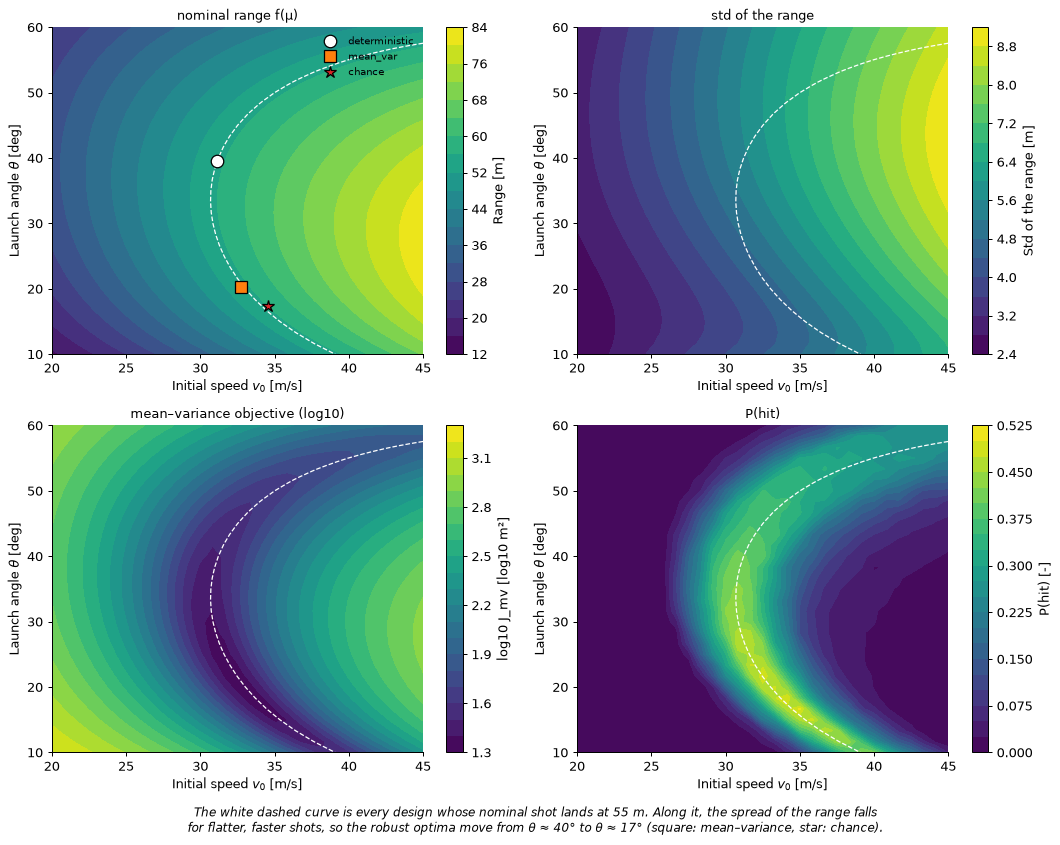

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
bh.plot_landscape(rob, "nominal", TARGET, ax=axes[0, 0], title="nominal range f(μ)", cbar_label="Range [m]")
bh.plot_landscape(rob, "std", TARGET, ax=axes[0, 1], title="std of the range", cbar_label="Std of the range [m]",
                  optima=False)
bh.plot_landscape(rob, "mean_var", TARGET, ax=axes[1, 0], title="mean–variance objective (log10)",
                  cbar_label="log10 J_mv [log10 m²]", log=True, optima=False)
bh.plot_landscape(rob, "p_hit", TARGET, ax=axes[1, 1], title="P(hit)", cbar_label="P(hit) [-]", optima=False)
det, cc = rob["optima"]["deterministic"]["x"], rob["optima"]["chance"]["x"]
bh.show(fig, f"The white dashed curve is every design whose nominal shot lands at {TARGET:g} m. Along it, "
             f"the spread of the range falls for flatter, faster shots, so the robust optima move from "
             f"θ ≈ {det['theta']:.0f}° to θ ≈ {cc['theta']:.0f}° (square: mean–variance, star: chance).")

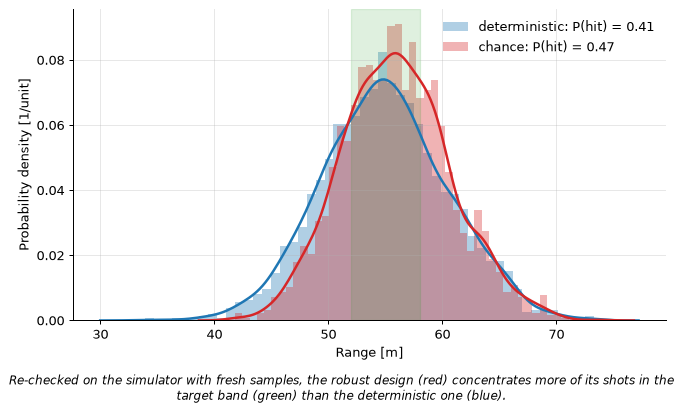

In [38]:
fig, ax = plt.subplots()
for kind, c in [("deterministic", "C0"), ("chance", "C3")]:
    v = np.asarray(rob["optima"][kind]["validation"]["values"])
    bh.plot_hist_kde(v, ax=ax, color=c, label_=f"{kind}: P(hit) = {rob['optima'][kind]['validation']['p_hit']:.2f}",
                     xlabel=bh.label("range"), quantiles=())
ax.axvspan(TARGET - TOL, TARGET + TOL, color="C2", alpha=0.15)
bh.show(fig, "Re-checked on the simulator with fresh samples, the robust design (red) concentrates more "
             "of its shots in the target band (green) than the deterministic one (blue).")

### Tolerance allocation

At the robust design, how does $P(\text{hit})$ depend on the execution tolerances (stds of $v_0$ and
θ)? The nuisance parameters (wind, $C_d$) stay as they are, so even a perfect shooter does not hit every
time: the wind caps the achievable probability.

P(hit) with perfect execution (std v0 = std θ = 0): 0.56  <- the cap set by the wind and Cd
P(hit) at the default tolerances (1 m/s, 1.5°): 0.47
P(hit) with perfect execution and no wind uncertainty (only Cd left): 0.64


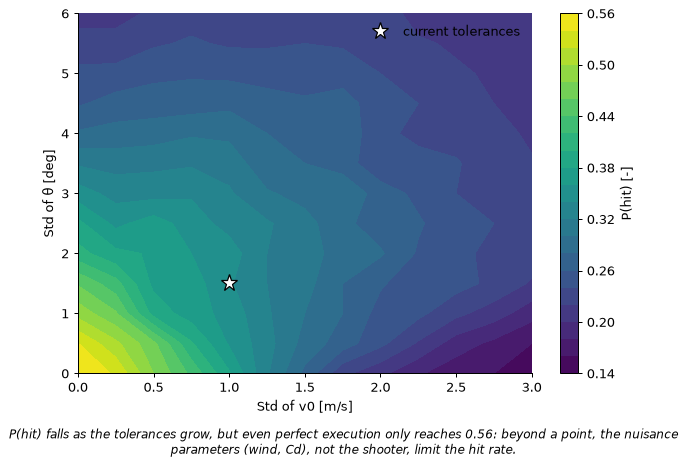

In [39]:
spec_rob = bh.spec_with(v0={"value": cc["v0"]}, theta={"value": cc["theta"]})
tol_study = robust.tolerance_study(spec_rob, ["v0", "theta"], "range", TARGET, TOL, std_max=[3.0, 6.0],
                                   grid=13, n_mc=400, seed=0)
P = np.array(tol_study["p_hit"])
s_v0, s_th = (np.array(a) for a in tol_study["axes"])
spec_calm = bh.spec_with(spec_rob, wind={"uncertain": False})
p_calm = robust.tolerance_study(spec_calm, ["v0", "theta"], "range", TARGET, TOL, std_max=[0.0, 0.0],
                                grid=1, n_mc=400, seed=0)["p_hit"][0][0]
print(f"P(hit) with perfect execution (std v0 = std θ = 0): {P[0, 0]:.2f}  <- the cap set by the wind and Cd")
print(f"P(hit) at the default tolerances (1 m/s, 1.5°): {rob['optima']['chance']['validation']['p_hit']:.2f}")
print(f"P(hit) with perfect execution and no wind uncertainty (only Cd left): {p_calm:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.8))
cs = ax.contourf(s_v0, s_th, P, levels=20, cmap="viridis")
plt.colorbar(cs, ax=ax, label="P(hit) [-]")
ax.plot(*tol_study["current_std"], "w*", ms=14, mec="k", label="current tolerances")
ax.set_xlabel("Std of v0 [m/s]")
ax.set_ylabel("Std of θ [deg]")
ax.legend()
ax.grid(False)
bh.show(fig, f"P(hit) falls as the tolerances grow, but even perfect execution only reaches {P[0, 0]:.2f}: "
             "beyond a point, the nuisance parameters (wind, Cd), not the shooter, limit the hit rate.")

**Takeaways**
- Optimising the nominal response ignores how sensitive the design is. Robust objectives prefer flatter,
  faster shots, which spend less time in the wind.
- Use common random numbers to compare designs; re-check the chosen designs on the true simulator with
  fresh samples (the surrogate and the CRN sample both bias the estimate a little).
- Tolerance studies show which uncertainties are worth reducing.

**Exercises**
1. Set `use_surrogate=False` and compare the optima and the run time. *Hint:* the landscape needs
   ~250 000 simulator runs.
2. Increase λ in the mean–variance objective to 5. *Hint:* the optimum trades more bias for less spread.
3. Double the wind std (`bh.spec_with(wind={"std": 4})`) and redo the tolerance study. What is the new cap?

## 7. Bayesian calibration

**Learning goals**
- Combine a prior and a likelihood into a posterior with Bayes' rule, exactly on a grid.
- See an identifiability problem (the $C_d$–mass ridge).
- Write a random-walk Metropolis sampler and compare it with the grid and with an ensemble MCMC.
- Use a GP emulator to make the likelihood cheap; propagate the posterior to predictions.
- See how unmodelled effects (model error) make the posterior overconfident.

**Setting.** $C_d$ is uncertain: prior $\mathcal N(0.25, 0.03^2)$. We fire 8 shots at launch angles from 15°
to 65° and measure their ranges with a noise of 1 m (std). The "true" $C_d$ of the synthetic experiment is
0.286, about one prior std above the prior mean. The launch angle is the *experimental condition*: it is
known and varied on purpose, not calibrated.

$$p(C_d \mid \mathbf y) \;\propto\; p(\mathbf y \mid C_d)\, p(C_d), \qquad
p(\mathbf y \mid C_d) = \prod_{k=1}^{8} \mathcal N\!\big(y_k \mid f(C_d, \theta_k),\, \sigma^2\big).$$

In [40]:
TRUE_CD = 0.286
exp1 = calibration.make_experiment(SPEC, ["cd"], {"cd": TRUE_CD}, n_obs=8, theta_range=(15, 65), noise=1.0, seed=0)
th_obs, y_obs = np.array(exp1["theta"]), np.array(exp1["obs"]["range"])
print("launch angles [deg]:", th_obs.round(1))
print("measured ranges [m]:", y_obs.round(2))

launch angles [deg]: [15.  22.1 29.3 36.4 43.6 50.7 57.9 65. ]
measured ranges [m]: [40.18 46.51 50.39 50.23 47.61 44.42 39.3  31.07]


### The posterior on a grid, by hand

With one parameter, the posterior can be computed exactly: evaluate prior × likelihood on a fine grid
(all grid points × all shots in one simulator call) and normalise.

prior     : mean 0.2500, std 0.0300
posterior : mean 0.2812, std 0.0049  (std shrinks 6.1x; truth 0.286)
matches uq_core.calibration.grid_posterior: True


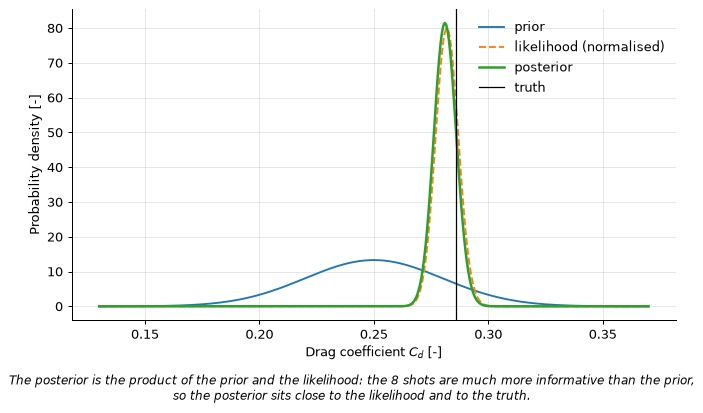

In [41]:
sigma = 1.0
(lo_cd, hi_cd), = params.box_from_spec(SPEC, ["cd"], k=4)     # prior mean ± 4 std
cd_grid = np.linspace(lo_cd, hi_cd, 400)
prior = params.marginal(SPEC["cd"])
pred = calibration.simulate_shots(SPEC, ["cd"], cd_grid[:, None], th_obs, ["range"], 0.01)["range"]  # (400, 8)
log_prior = prior.logpdf(cd_grid)
log_lik = -0.5 * np.sum(((pred - y_obs) / sigma) ** 2, axis=1)
log_post = log_prior + log_lik
dx = cd_grid[1] - cd_grid[0]
normalise = lambda lp: np.exp(lp - lp.max()) / (np.exp(lp - lp.max()).sum() * dx)  # noqa: E731
post_pdf, lik_pdf = normalise(log_post), normalise(log_lik)
post_mean = np.sum(cd_grid * post_pdf) * dx
post_std = np.sqrt(np.sum((cd_grid - post_mean) ** 2 * post_pdf) * dx)
print(f"prior     : mean {prior.mean():.4f}, std {prior.std():.4f}")
print(f"posterior : mean {post_mean:.4f}, std {post_std:.4f}  (std shrinks {prior.std() / post_std:.1f}x; truth {TRUE_CD})")

post1 = calibration.Posterior(SPEC, ["cd"], th_obs, {"range": y_obs}, sigma, 0.01)
grid_core = calibration.grid_posterior(post1)
print("matches uq_core.calibration.grid_posterior:", np.allclose(grid_core["marginals"][0], post_pdf))

fig, ax = plt.subplots()
ax.plot(cd_grid, prior.pdf(cd_grid), label="prior")
ax.plot(cd_grid, lik_pdf, "--", label="likelihood (normalised)")
ax.plot(cd_grid, post_pdf, lw=2, label="posterior")
ax.axvline(TRUE_CD, color="k", lw=1, label="truth")
ax.set_xlabel(bh.label("cd"))
ax.set_ylabel("Probability density [-]")
ax.legend()
bh.show(fig, "The posterior is the product of the prior and the likelihood: the 8 shots are much more "
             "informative than the prior, so the posterior sits close to the likelihood and to the truth.")

### Posterior predictive

What does calibration buy us? Predictions: propagate the prior and the posterior samples of $C_d$ through
the simulator (the other inputs at nominal) and compare the predicted ranges, for example of a new shot at
45°. `uq_core.calibration.calibrate` packages this.

range of a new 45° shot: prior 50.7 ± 2.71 m, posterior 47.9 ± 0.39 m (truth 47.5 m)


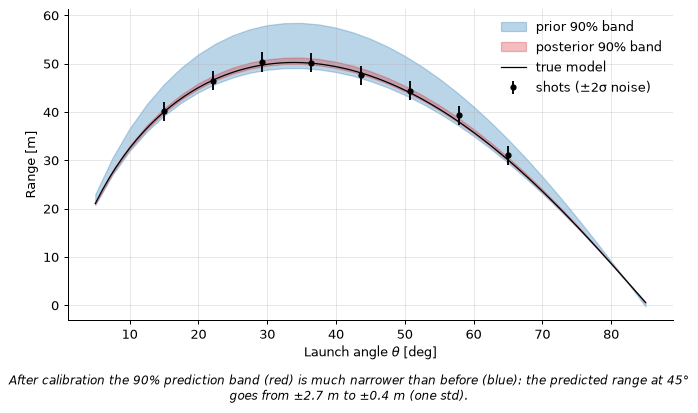

In [42]:
cal1 = calibration.calibrate(SPEC, ["cd"], th_obs, {"range": y_obs}, sigma, method="grid", theta_new=45.0,
                             truth={"cd": TRUE_CD}, seed=0)
pr, po = cal1["prediction"]["prior"], cal1["prediction"]["posterior"]
print(f"range of a new 45° shot: prior {pr['mean']:.1f} ± {pr['std']:.2f} m, posterior {po['mean']:.1f} ± "
      f"{po['std']:.2f} m (truth {cal1['prediction']['truth']:.1f} m)")

pc = cal1["predictive_curve"]
fig, ax = plt.subplots()
for band, c in [("prior", "C0"), ("posterior", "C3")]:
    ax.fill_between(pc["theta"], pc[band]["p05"], pc[band]["p95"], color=c, alpha=0.3, label=f"{band} 90% band")
ax.plot(exp1["true_curve"]["theta"], exp1["true_curve"]["range"], "k-", lw=1, label="true model")
ax.errorbar(th_obs, y_obs, yerr=2 * sigma, fmt="o", color="k", ms=4, label="shots (±2σ noise)")
ax.set_xlabel(bh.label("theta"))
ax.set_ylabel(bh.label("range"))
ax.legend()
bh.show(fig, f"After calibration the 90% prediction band (red) is much narrower than before (blue): the "
             f"predicted range at 45° goes from ±{pr['std']:.1f} m to ±{po['std']:.1f} m (one std).")

### Identifiability: calibrating $C_d$ and the mass together

Since only $C_d/m$ enters the equations, the data constrain the ratio, not each parameter. With a wide
mass prior (std 0.1 kg), the joint posterior is a ridge along $C_d/m = \text{const}$.

prior coefficient of variation: Cd 12.0%, mass 23.3%
posterior correlation(Cd, m) = 0.94
posterior coefficient of variation: Cd 5.7%, mass 6.1%, Cd/m 2.1%


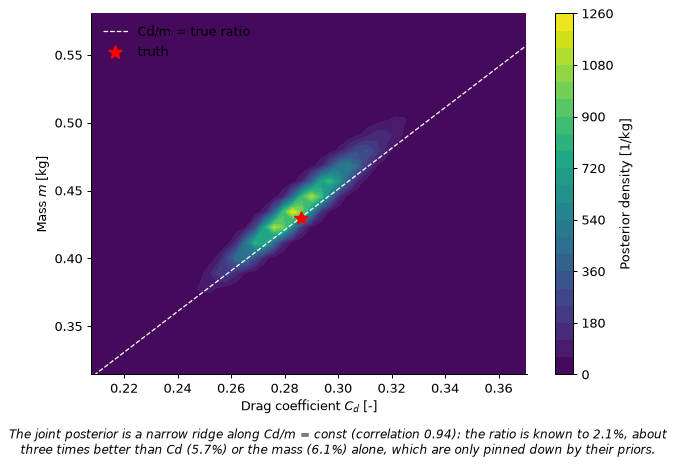

In [43]:
spec2 = bh.spec_with(mass={"std": 0.1, "uncertain": True})
exp2 = calibration.make_experiment(spec2, ["cd", "mass"], {"cd": TRUE_CD, "mass": 0.43}, n_obs=8, noise=1.0, seed=0)
post2 = calibration.Posterior(spec2, ["cd", "mass"], exp2["theta"], exp2["obs"], 1.0, 0.01)
g2 = calibration.grid_posterior(post2, seed=0)
S2 = g2["samples"]
corr = np.corrcoef(S2.T)[0, 1]
ratio = S2[:, 0] / S2[:, 1]
cv = lambda v: v.std() / v.mean()  # noqa: E731
print(f"prior coefficient of variation: Cd {0.03 / 0.25:.1%}, mass {0.1 / 0.43:.1%}")
print(f"posterior correlation(Cd, m) = {corr:.2f}")
print(f"posterior coefficient of variation: Cd {cv(S2[:, 0]):.1%}, mass {cv(S2[:, 1]):.1%}, Cd/m {cv(ratio):.1%}")

fig, ax = plt.subplots(figsize=(7, 4.8))
a0, a1 = (np.array(a) for a in g2["axes"])
cs = ax.contourf(a0, a1, np.array(g2["pairs"][0]["density"]), levels=20, cmap="viridis")
plt.colorbar(cs, ax=ax, label="Posterior density [1/kg]")
ax.plot(a0, a0 * 0.43 / TRUE_CD, "w--", lw=1, label="Cd/m = true ratio")
ax.plot(TRUE_CD, 0.43, "r*", ms=12, label="truth")
lo_s, hi_s = np.percentile(S2, [0.1, 99.9], axis=0)
pad = 0.3 * (hi_s - lo_s)
ax.set_xlim(lo_s[0] - pad[0], hi_s[0] + pad[0])
ax.set_ylim(lo_s[1] - pad[1], hi_s[1] + pad[1])
ax.set_xlabel(bh.label("cd"))
ax.set_ylabel(bh.label("mass"))
ax.legend()
ax.grid(False)
bh.show(fig, f"The joint posterior is a narrow ridge along Cd/m = const (correlation {corr:.2f}): the ratio "
             f"is known to {cv(ratio):.1%}, about three times better than Cd ({cv(S2[:, 0]):.1%}) or the mass "
             f"({cv(S2[:, 1]):.1%}) alone, which are only pinned down by their priors.")

### MCMC: random-walk Metropolis by hand

A grid is exact but costs $n^d$ evaluations: it is hopeless beyond 2–3 parameters. Markov chain Monte
Carlo (MCMC) samples the posterior instead. **Random-walk Metropolis**: propose
$\mathbf x' = \mathbf x + \delta\,\boldsymbol\epsilon$, $\boldsymbol\epsilon \sim \mathcal N(0, I)$, and accept it with
probability $\min\!\big(1, p(\mathbf x' \mid \mathbf y)/p(\mathbf x \mid \mathbf y)\big)$; otherwise stay.
Only ratios of the posterior are needed, so its normalising constant never appears.

The step δ must be tuned. Too small: almost every move is accepted, but the chain crawls. Too large: almost
every move is rejected. We run 4 chains for each of 3 step sizes, all advanced together in one vectorised
call per iteration.

Metropolis on the simulator: 5.68 s
step 0.0005 : acceptance 0.91, posterior mean 0.2778, std 0.0124
step 0.005  : acceptance 0.71, posterior mean 0.2814, std 0.0048
step 0.05   : acceptance 0.12, posterior mean 0.2809, std 0.0050


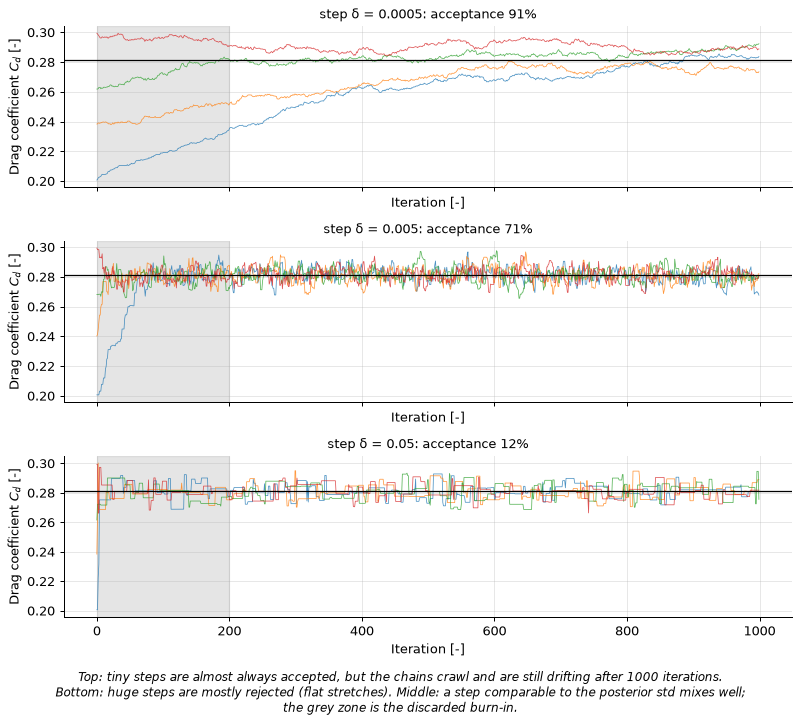

In [44]:
def metropolis(log_post, x0, step, n_iter, seed=0):
    # Random-walk Metropolis for several independent chains at once. x0: (C, d), step: (C, 1)
    rng = np.random.default_rng(seed)
    x = np.array(x0, dtype=float)
    lp = log_post(x)
    chain = np.empty((n_iter, *x.shape))
    accepted = np.zeros(len(x))
    for t in range(n_iter):
        prop = x + step * rng.standard_normal(x.shape)
        lp_prop = log_post(prop)
        accept = np.log(rng.random(len(x))) < lp_prop - lp
        x[accept], lp[accept] = prop[accept], lp_prop[accept]
        accepted += accept
        chain[t] = x
    return chain, accepted / n_iter

steps = [0.0005, 0.005, 0.05]
n_chains, n_iter, burn = 4, 1000, 200
x0 = np.tile(prior.ppf([0.05, 0.35, 0.65, 0.95]), len(steps))[:, None]      # spread starting points
step_col = np.repeat(steps, n_chains)[:, None]
with bh.timer("Metropolis on the simulator"):
    chain, acc = metropolis(post1, x0, step_col, n_iter, seed=0)
for k_, s_ in enumerate(steps):
    c = chain[burn:, k_ * n_chains:(k_ + 1) * n_chains, 0]
    print(f"step {s_:<7}: acceptance {acc[k_ * n_chains:(k_ + 1) * n_chains].mean():.2f}, "
          f"posterior mean {c.mean():.4f}, std {c.std():.4f}")

fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
for k_, s_ in enumerate(steps):
    bh.plot_traces(chain[:, k_ * n_chains:(k_ + 1) * n_chains, :], ["cd"], burn=burn, ax=[axes[k_]],
                   title=f"step δ = {s_}: acceptance {acc[k_ * n_chains:(k_ + 1) * n_chains].mean():.0%}")
    axes[k_].axhline(post_mean, color="k", lw=1)
axes[-1].set_xlabel("Iteration [-]")
bh.show(fig, "Top: tiny steps are almost always accepted, but the chains crawl and are still drifting "
             "after 1000 iterations. Bottom: huge steps are mostly rejected (flat stretches). Middle: a step comparable "
             "to the posterior std mixes well; the grey zone is the discarded burn-in.")

The **affine-invariant ensemble sampler** (stretch move, Goodman & Weare 2010; the algorithm behind
`emcee`) moves each walker along the line through another walker. It adapts to the scale and the
correlations of the posterior by itself: no step size to tune. `uq_core` implements it in
`stretch_mcmc`. Comparison of the three estimates of the posterior:

stretch MCMC on the simulator: 3.41 s
method                 | mean   | std    | simulator runs
grid (exact)           | 0.2812 | 0.0049 | 3200
Metropolis (δ=0.005)   | 0.2814 | 0.0048 | 32000
stretch (32 walkers)   | 0.2813 | 0.0047 | 77056
stretch acceptance rate: 0.79


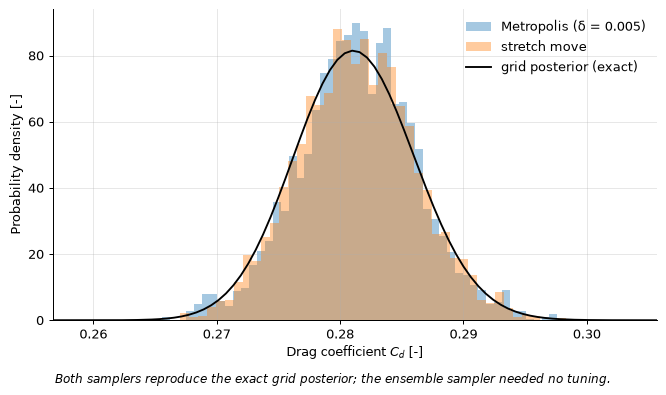

In [45]:
good = chain[burn:, n_chains:2 * n_chains, 0].ravel()
with bh.timer("stretch MCMC on the simulator"):
    runs0 = post1.model_runs
    ens = calibration.stretch_mcmc(post1, n_walkers=32, n_iter=300, burn=100, seed=0)
    ens_runs = post1.model_runs - runs0
print(f"{'method':22s} | mean   | std    | simulator runs")
print(f"{'grid (exact)':22s} | {post_mean:.4f} | {post_std:.4f} | {len(cd_grid) * len(th_obs)}")
print(f"{'Metropolis (δ=0.005)':22s} | {good.mean():.4f} | {good.std():.4f} | {n_chains * n_iter * len(th_obs)}")
print(f"{'stretch (32 walkers)':22s} | {ens['samples'][:, 0].mean():.4f} | {ens['samples'][:, 0].std():.4f} | {ens_runs}")
print(f"stretch acceptance rate: {ens['acceptance']:.2f}")

fig, ax = plt.subplots()
ax.hist(good, bins=50, density=True, alpha=0.4, label="Metropolis (δ = 0.005)")
ax.hist(ens["samples"][:, 0], bins=50, density=True, alpha=0.4, label="stretch move")
ax.plot(cd_grid, post_pdf, "k", lw=1.5, label="grid posterior (exact)")
ax.set_xlim(post_mean - 5 * post_std, post_mean + 5 * post_std)
ax.set_xlabel(bh.label("cd"))
ax.set_ylabel("Probability density [-]")
ax.legend()
bh.show(fig, "Both samplers reproduce the exact grid posterior; the ensemble sampler needed no tuning.")

### A GP emulator for the likelihood

Each likelihood evaluation runs the simulator once per shot. With an expensive simulator, MCMC's thousands
of evaluations become unaffordable. Solution: train a GP **emulator** of the range as a function of
($C_d$, θ) on a small design, and run the MCMC on the emulator.

In [46]:
with bh.timer("train the emulator"):
    emus, emu_info = calibration.train_emulators(SPEC, ["cd"], (15.0, 65.0), ["range"], 0.01, n_train=40, seed=0)
print(f"emulator: {emu_info['n_train']} simulator runs, test Q² = {emu_info['scores']['range']['r2']:.5f}, "
      f"RMSE = {emu_info['scores']['range']['rmse']:.3f} m")
post_emu = calibration.Posterior(SPEC, ["cd"], th_obs, {"range": y_obs}, sigma, 0.01, emulators=emus)
with bh.timer("stretch MCMC on the emulator"):
    ens_emu = calibration.stretch_mcmc(post_emu, n_walkers=32, n_iter=300, burn=100, seed=0)
print(f"posterior with the emulator: mean {ens_emu['samples'][:, 0].mean():.4f}, std {ens_emu['samples'][:, 0].std():.4f} "
      f"(simulator: {ens['samples'][:, 0].mean():.4f}, {ens['samples'][:, 0].std():.4f})")
print(f"simulator runs: {emu_info['n_train']} with the emulator vs {ens_runs} without")

train the emulator: 0.15 s
emulator: 40 simulator runs, test Q² = 1.00000, RMSE = 0.005 m
stretch MCMC on the emulator: 0.15 s
posterior with the emulator: mean 0.2813, std 0.0047 (simulator: 0.2813, 0.0047)
simulator runs: 40 with the emulator vs 77056 without


### Model error: unmodelled gusts

So far the calibration model was exactly the model that generated the data. In reality, models miss
things. Here each shot is perturbed by a random wind gust (std 3 m/s) that the calibration model ignores.
For 10 synthetic datasets of 12 shots each, we check whether the 95% posterior interval contains the true
$C_d$, first with the nominal noise σ = 1 m, then with an inflated σ = 4 m that absorbs the model error.

no gusts, σ = 1 : the 95% interval contains the truth in 10/10 datasets
gusts, σ = 1    : the 95% interval contains the truth in 4/10 datasets
gusts, σ = 4    : the 95% interval contains the truth in 9/10 datasets


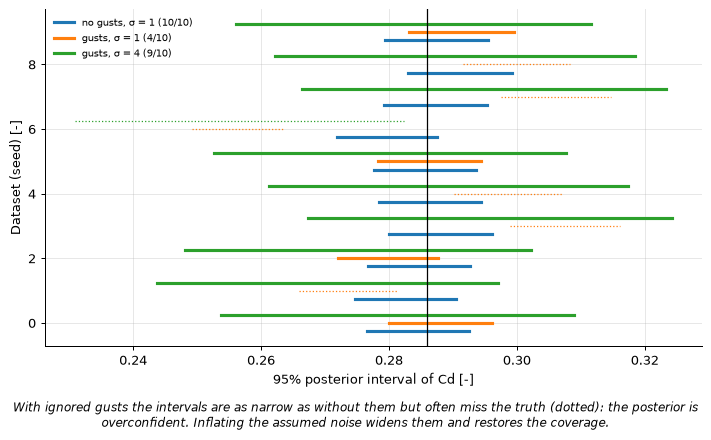

In [47]:
def credible_interval(exp_, sigma_):
    post_ = calibration.Posterior(SPEC, ["cd"], exp_["theta"], exp_["obs"], sigma_, 0.01)
    s_ = calibration.grid_posterior(post_, seed=0)["samples"][:, 0]
    return np.percentile(s_, [2.5, 97.5])

cases = [("no gusts, σ = 1", 0.0, 1.0), ("gusts, σ = 1", 3.0, 1.0), ("gusts, σ = 4", 3.0, 4.0)]
cis = {lab: [] for lab, _, _ in cases}
for seed in range(10):
    for lab, gust, sig in cases:
        ex = calibration.make_experiment(SPEC, ["cd"], {"cd": TRUE_CD}, n_obs=12, noise=1.0, gust_std=gust, seed=seed)
        cis[lab].append(credible_interval(ex, sig))
coverage = {lab: int(sum(lo_ <= TRUE_CD <= hi_ for lo_, hi_ in v)) for lab, v in cis.items()}
for lab, c in coverage.items():
    print(f"{lab:16s}: the 95% interval contains the truth in {c}/10 datasets")

fig, ax = plt.subplots(figsize=(8, 4.5))
for k_, (lab, _, _) in enumerate(cases):
    for seed, (lo_, hi_) in enumerate(cis[lab]):
        hit = lo_ <= TRUE_CD <= hi_
        ax.plot([lo_, hi_], [seed + 0.25 * (k_ - 1)] * 2, color=f"C{k_}", lw=2.5 if hit else 1,
                ls="-" if hit else ":", label=f"{lab} ({coverage[lab]}/10)" if seed == 0 else None)
ax.axvline(TRUE_CD, color="k", lw=1)
ax.set_xlabel("95% posterior interval of Cd [-]")
ax.set_ylabel("Dataset (seed) [-]")
ax.legend(fontsize=8)
bh.show(fig, "With ignored gusts the intervals are as narrow as without them but often miss the truth "
             "(dotted): the posterior is overconfident. Inflating the assumed noise widens them and "
             "restores the coverage.")

**Takeaways**
- Posterior ∝ likelihood × prior. Eight shots shrink the $C_d$ std about 6×, and the predictions
  inherit the reduction.
- Data constrain only what the model can distinguish: here $C_d/m$, not $C_d$ and $m$ separately.
- A grid is exact in 1–2 dimensions; MCMC scales better. Random-walk Metropolis needs a tuned step; the
  ensemble sampler does not. A GP emulator cuts the simulator runs by orders of magnitude.
- A posterior is only as good as the model: ignored model error makes it overconfident. Inflating the
  noise is a crude but effective fix; a principled one adds a model-discrepancy term (Kennedy & O'Hagan).

**Exercises**
1. Calibrate with 3 shots instead of 8, or with a noise of 3 m. *Hint:* the posterior moves back
   towards the prior.
2. In the 2D case, add a measurement of the max height (`qois=["range", "max_height"]`). Does it break
   the ridge? *Hint:* the max height also depends on $C_d/m$ only.
3. Run the Metropolis sampler on the 2D $C_d$–mass posterior with an isotropic step. *Hint:* along the
   ridge the step must be small to be accepted, so mixing along the ridge is slow; this is where the
   affine-invariant ensemble shines.

## 8. Wrap-up

The sections form one workflow:

```
 model (§0–1)  →  input uncertainty (§2)  →  design of experiments (§3)  →  surrogate (§4)
                                                                               │
                         ┌─────────────────────────────────────────────────────┤
                         ▼                          ▼                          ▼
           sensitivity analysis (§5)      robust optimisation (§6)    Bayesian calibration (§7)
         which uncertainties matter?     which design is reliable?    what do data tell us?
                         └──────────── reduce / measure what matters ──────────┘
```

1. **Understand the model** and its numerical error before adding uncertainty.
2. **Describe the input uncertainties** with laws; state the conventions (mean and std of $X$ itself).
3. **Propagate**: Monte Carlo is the reference; LHS and QMC accelerate it; FOSM is a cheap first look.
4. **When the model is expensive**, spend the runs on a space-filling design and train a surrogate, and
   validate it on independent data.
5. **Rank the inputs** (screening with Morris, then Sobol) to know where to spend effort.
6. **Design under uncertainty**: compare robust objectives with common random numbers, and re-check on the
   true model.
7. **Learn from data**: calibrate with Bayes, check identifiability, and be wary of model error.

**The interactive app.** The same model and methods, with sliders and live plots, are in the Ballistic UQ
Lab: see `uq_demo/README.md` (`uvicorn api.main:app`, one tab per section of this notebook).

**Further reading**
- R. C. Smith, *Uncertainty Quantification: Theory, Implementation, and Applications*, SIAM, 2014.
- A. Saltelli et al., *Global Sensitivity Analysis: The Primer*, Wiley, 2008; Saltelli et al., "Variance
  based sensitivity analysis of model output", *Comput. Phys. Commun.* 181, 2010.
- C. E. Rasmussen & C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006
  (free online).
- T. J. Santner, B. J. Williams & W. I. Notz, *The Design and Analysis of Computer Experiments*, Springer, 2018.
- J. Goodman & J. Weare, "Ensemble samplers with affine invariance", *CAMCoS* 5, 2010.
- M. C. Kennedy & A. O'Hagan, "Bayesian calibration of computer models", *J. R. Stat. Soc. B* 63, 2001.

In [48]:
print(f"total notebook run time: {time.perf_counter() - NOTEBOOK_START:.0f} s")

total notebook run time: 35 s
